In [25]:
# CELL 1: NOTEBOOK 05 SETUP

import pandas as pd
import numpy as np
import os
import ast
import warnings

warnings.filterwarnings("ignore")

# --------------------------------------------------
# PATHS
# --------------------------------------------------

PROCESSED_DIR = "../processed_data"
RESULTS_DIR = "../results"

os.makedirs(RESULTS_DIR, exist_ok=True)

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

training_interactions = pd.read_csv(
    os.path.join(PROCESSED_DIR, "training_interactions.csv")
)

testing_interactions = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testing_interactions.csv")
)

video_creator_map = pd.read_csv(
    os.path.join(PROCESSED_DIR, "video_creator_map.csv")
)

video_creator_groups = pd.read_csv(
    os.path.join(PROCESSED_DIR, "video_creator_groups.csv")
)

creator_popularity = pd.read_csv(
    os.path.join(PROCESSED_DIR, "creator_popularity.csv")
)

video_metadata = pd.read_csv(
    os.path.join(PROCESSED_DIR, "video_metadata.csv")
)

interest_profiles = pd.read_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv")
)

baseline_recommendations = pd.read_csv(
    os.path.join(RESULTS_DIR, "baseline_recommendations.csv")
)

spotlight_recommendations = pd.read_csv(
    os.path.join(RESULTS_DIR, "spotlight_constrained_recommendations.csv")
)

spotlight_candidate_pool = pd.read_csv(
    os.path.join(RESULTS_DIR, "spotlight_candidate_pool.csv")
)

spotlight_exploration_selections = pd.read_csv(
    os.path.join(RESULTS_DIR, "spotlight_constrained_selections.csv")
)

# --------------------------------------------------
# BASIC DATASET INFORMATION
# --------------------------------------------------

datasets = {
    "Training Interactions": training_interactions,
    "Testing Interactions": testing_interactions,
    "Video Creator Map": video_creator_map,
    "Video Creator Groups": video_creator_groups,
    "Creator Popularity": creator_popularity,
    "Video Metadata": video_metadata,
    "Interest Profiles": interest_profiles,
    "Baseline Recommendations": baseline_recommendations,
    "Spotlight Recommendations": spotlight_recommendations,
    "Candidate Pool": spotlight_candidate_pool,
    "Exploration Selections": spotlight_exploration_selections
}

print("=" * 100)
print("NOTEBOOK 05 — EXPLORATION STRATEGY")
print("=" * 100)

for name, df in datasets.items():
    print(f"{name:30} | Shape: {df.shape}")

print("\n✅ DATA LOADING COMPLETED!")

NOTEBOOK 05 — EXPLORATION STRATEGY
Training Interactions          | Shape: (4387382, 9)
Testing Interactions           | Shape: (107196, 9)
Video Creator Map              | Shape: (3327, 2)
Video Creator Groups           | Shape: (3327, 4)
Creator Popularity             | Shape: (2020, 5)
Video Metadata                 | Shape: (3327, 12)
Interest Profiles              | Shape: (40918, 4)
Baseline Recommendations       | Shape: (14110, 3)
Spotlight Recommendations      | Shape: (14110, 3)
Candidate Pool                 | Shape: (70550, 4)
Exploration Selections         | Shape: (804, 8)

✅ DATA LOADING COMPLETED!


In [26]:
# DIAGNOSTIC: CHECK ACTUAL RESULT FILE NAMES

print("RESULTS DIRECTORY:", os.path.abspath(RESULTS_DIR))
print("\nFiles currently available:\n")

for file in sorted(os.listdir(RESULTS_DIR)):
    print(file)

RESULTS DIRECTORY: c:\Users\Shrutee Patil\Desktop\MSC Part 2 Sem 3\Research Project\Spotlight_project\results

Files currently available:

baseline_catalogue_coverage.csv
baseline_creator_exposure_detail.csv
baseline_creator_level_metrics.csv
baseline_group_exposure.csv
baseline_ranking_metrics.csv
baseline_recommendations.csv
baseline_user_diversity.csv
baseline_user_novelty.csv
baseline_user_ranking_metrics.csv
combined_statistical_evidence.csv
diversity_bootstrap_distributions.csv
diversity_bootstrap_holm_results.csv
diversity_metric_changes.csv
diversity_summary.csv
final_spotlight_comparison.csv
notebook04_final_validation.csv
notebook04_research_summary.txt
notebook05_baseline_creator_exposure_detail.csv
notebook05_baseline_user_ranking_metrics.csv
notebook05_benefit_concentration.csv
notebook05_corrected_exposure_ratio_audit.csv
notebook05_creator_benefit_statistics.csv
notebook05_creator_concentration_comparison.csv
notebook05_creator_gain_frequency.csv
notebook05_emerging_crea

In [27]:
# CELL 2: INSPECT AVAILABLE RECOMMENDATION ARTIFACTS

files_to_inspect = [
    "baseline_recommendations.csv",
    "spotlight_candidate_pool.csv",
    "final_spotlight_comparison.csv",
    "spotlight_user_ranking_metrics.csv",
    "spotlight_user_diversity.csv",
    "spotlight_user_novelty.csv"
]

for filename in files_to_inspect:

    filepath = os.path.join(RESULTS_DIR, filename)

    print("\n" + "=" * 90)
    print(f"FILE: {filename}")
    print("=" * 90)

    if os.path.exists(filepath):

        df = pd.read_csv(filepath)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nFirst 5 rows:")
        display(df.head())

    else:

        print("❌ FILE NOT FOUND")


FILE: baseline_recommendations.csv
Shape: (14110, 3)
Columns: ['user_id', 'video_id', 'predicted_preference']

First 5 rows:


,user_id,video_id,predicted_preference
0,14,3992,0.997153
1,14,7263,0.995710
2,14,835,0.990655
3,14,6177,0.990421
4,14,6086,0.966525



FILE: spotlight_candidate_pool.csv
Shape: (70550, 4)
Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank']

First 5 rows:


,user_id,video_id,predicted_preference,candidate_rank
0,14,3992,0.997153,1
1,14,7263,0.995710,2
2,14,835,0.990655,3
3,14,6177,0.990421,4
4,14,4026,0.974648,5



FILE: final_spotlight_comparison.csv
Shape: (18, 5)
Columns: ['Metric', 'Baseline', 'Spotlight', 'Absolute_Change', 'Relative_Change_Percent']

First 5 rows:


,Metric,Baseline,Spotlight,Absolute_Change,Relative_Change_Percent
0,Precision@10,0.139405,0.136003,-0.003402,-2.440372
1,Recall@10,0.037370,0.036405,-0.000965,-2.582285
2,NDCG@10,0.139410,0.137262,-0.002148,-1.540779
3,HitRate@10,0.696669,0.691708,-0.004961,-0.712103
4,Unique Creators@10,9.756910,9.772502,0.015592,0.159805


... (2 outputs left out)


FILE: spotlight_user_diversity.csv
Shape: (1411, 7)
Columns: ['user_id', 'Model', 'Unique_Creators@10', 'Unique_Categories@10', 'Creator_Diversity@10', 'Creator_Pairwise_Diversity', 'Category_Pairwise_Diversity']

First 5 rows:


,user_id,Model,Unique_Creators@10,Unique_Categories@10,Creator_Diversity@10,Creator_Pairwise_Diversity,Category_Pairwise_Diversity
0,14,Spotlight,10,12,1.0,1.000000,0.947407
1,19,Spotlight,10,8,1.0,1.000000,0.851852
2,21,Spotlight,9,8,0.9,0.977778,0.550000
3,23,Spotlight,10,9,1.0,1.000000,0.911111
4,24,Spotlight,10,8,1.0,1.000000,0.888889



FILE: spotlight_user_novelty.csv
Shape: (1411, 7)
Columns: ['user_id', 'Model', 'Novelty@10', 'Mean_Popularity@10', 'Median_Popularity@10', 'Popularity_Metadata_Coverage@10', 'Valid_Recommendations']

First 5 rows:


,user_id,Model,Novelty@10,Mean_Popularity@10,Median_Popularity@10,Popularity_Metadata_Coverage@10,Valid_Recommendations
0,14,Spotlight,12.831259,440107.378816,355109.139787,1.0,10
1,19,Spotlight,13.862913,251861.740991,156558.296203,1.0,10
2,21,Spotlight,13.545574,188921.289091,199008.250206,1.0,10
3,23,Spotlight,14.353633,129851.247636,28233.600000,1.0,10
4,24,Spotlight,13.942713,212972.310407,115727.013587,1.0,10


In [28]:
# CELL 3: INSPECT SAVED EXPLORATION SELECTIONS

selection_path = os.path.join(
    RESULTS_DIR,
    "spotlight_constrained_selections.csv"
)

if os.path.exists(selection_path):

    spotlight_exploration_selections = pd.read_csv(
        selection_path
    )

    print("File found!")
    print("Shape:", spotlight_exploration_selections.shape)
    print("\nColumns:")
    print(spotlight_exploration_selections.columns.tolist())

    print("\nFirst 10 rows:")
    display(spotlight_exploration_selections.head(10))

    print("\nUnique users:", spotlight_exploration_selections["user_id"].nunique())
    print("Unique videos:", spotlight_exploration_selections["video_id"].nunique())

else:

    print("❌ Exploration selections file not found.")

File found!
Shape: (804, 8)

Columns:
['user_id', 'exploration_video', 'exploration_creator', 'exploration_score', 'baseline_removed_video', 'baseline_removed_score', 'score_difference', 'relevance_cost']

First 10 rows:


,user_id,exploration_video,exploration_creator,exploration_score,baseline_removed_video,baseline_removed_score,score_difference,relevance_cost
0,14,770,536,0.829176,4268,0.945336,-0.116160,0.116160
1,23,7654,3964,0.918251,7248,0.994966,-0.076715,0.076715
2,36,870,4120,0.933105,5205,0.957730,-0.024625,0.024625
3,41,8607,2954,0.895724,8515,0.947379,-0.051655,0.051655
4,51,136,3542,0.841327,2436,0.968694,-0.127367,0.127367
5,55,4172,116,0.982925,8204,0.996173,-0.013248,0.013248
6,75,8309,3944,0.862205,541,0.963442,-0.101237,0.101237
7,120,4758,849,0.800903,3965,0.804387,-0.003484,0.003484
8,127,702,5448,1.000000,166,1.000000,0.000000,0.000000
9,129,5228,1756,0.792808,4184,0.923140,-0.130332,0.130332



Unique users: 804


KeyError: 'video_id'

In [29]:
# RECOVERY CHECK: NOTEBOOK 04 VARIABLES

variables_to_check = [
    "spotlight_constrained_selections",
    "spotlight_constrained_recommendations",
    "exploration_score_comparison",
    "spotlight_candidate_pool",
    "underexposed_emerging",
    "eligible_exploration_candidates"
]

for var_name in variables_to_check:

    exists = var_name in globals()

    print(f"{var_name}: {'AVAILABLE' if exists else 'NOT FOUND'}")

    if exists:
        obj = globals()[var_name]

        if isinstance(obj, pd.DataFrame):
            print("   Shape:", obj.shape)
            print("   Columns:", obj.columns.tolist())

spotlight_constrained_selections: NOT FOUND
spotlight_constrained_recommendations: NOT FOUND
exploration_score_comparison: NOT FOUND
spotlight_candidate_pool: AVAILABLE
   Shape: (70550, 4)
   Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank']
underexposed_emerging: NOT FOUND
eligible_exploration_candidates: NOT FOUND


In [30]:

# CELL 2: RECOVER ORIGINAL SPOTLIGHT EXPLORATION ARTIFACTS

import pandas as pd
import numpy as np
import ast
import os

# --------------------------------------------------
# 1. LOAD REQUIRED SAVED ARTIFACTS
# --------------------------------------------------

candidate_pool = pd.read_csv(
    os.path.join(RESULTS_DIR, "spotlight_candidate_pool.csv")
)

baseline_recs = pd.read_csv(
    os.path.join(RESULTS_DIR, "baseline_recommendations.csv")
)

creator_groups = pd.read_csv(
    os.path.join(PROCESSED_DIR, "video_creator_groups.csv")
)

video_meta = pd.read_csv(
    os.path.join(PROCESSED_DIR, "video_metadata.csv")
)

user_profiles = pd.read_csv(
    os.path.join(PROCESSED_DIR, "interest_profiles.csv")
)

# --------------------------------------------------
# 2. REBUILD CANDIDATE FEATURES
# --------------------------------------------------

features = candidate_pool.merge(
    creator_groups[["video_id", "author_id", "creator_group"]],
    on="video_id",
    how="left"
)

features = features.merge(
    video_meta[["video_id", "category_ids"]],
    on="video_id",
    how="left"
)

def parse_categories(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError):
        return []

features["category_ids"] = features["category_ids"].apply(
    parse_categories
)

# --------------------------------------------------
# 3. REBUILD USER-VIDEO INTEREST SCORES
# --------------------------------------------------

user_interest_weights = user_profiles[
    ["user_id", "category_ids", "interest_weight"]
].copy()

user_interest_weights = user_interest_weights.rename(
    columns={"category_ids": "category_id"}
)

user_interest_weights["category_id"] = (
    pd.to_numeric(user_interest_weights["category_id"])
    .astype(int)
)

candidate_category_data = features[
    ["user_id", "video_id", "category_ids"]
].explode("category_ids")

candidate_category_data = candidate_category_data.rename(
    columns={"category_ids": "category_id"}
).dropna(subset=["category_id"])

candidate_category_data["category_id"] = (
    pd.to_numeric(candidate_category_data["category_id"])
    .astype(int)
)

candidate_interest_matches = candidate_category_data.merge(
    user_interest_weights,
    on=["user_id", "category_id"],
    how="left",
    validate="many_to_one"
)

video_interest_scores = (
    candidate_interest_matches
    .groupby(["user_id", "video_id"])["interest_weight"]
    .mean()
    .reset_index()
    .rename(
        columns={"interest_weight": "interest_match_score"}
    )
)

features = features.merge(
    video_interest_scores,
    on=["user_id", "video_id"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 4. REBUILD WITHIN-USER PERCENTILES
# --------------------------------------------------

features["cf_percentile"] = (
    features.groupby("user_id")["predicted_preference"]
    .rank(method="average", pct=True)
)

features["interest_percentile"] = (
    features.groupby("user_id")["interest_match_score"]
    .rank(method="average", pct=True)
)

# Original interest eligibility threshold
features["interest_eligible"] = (
    features["interest_percentile"] >= 0.30
)

# --------------------------------------------------
# 5. REBUILD ELIGIBLE USER-CREATOR OPPORTUNITIES
# --------------------------------------------------

eligible_user_creator_pairs = (
    features[features["interest_eligible"]]
    [["user_id", "author_id", "creator_group"]]
    .drop_duplicates()
)

baseline_with_creator = baseline_recs.merge(
    creator_groups[
        ["video_id", "author_id", "creator_group"]
    ],
    on="video_id",
    how="left"
)

baseline_user_creator_pairs = (
    baseline_with_creator[
        ["user_id", "author_id", "creator_group"]
    ]
    .drop_duplicates()
)

eligible_exposed_pairs = eligible_user_creator_pairs.merge(
    baseline_user_creator_pairs[
        ["user_id", "author_id"]
    ],
    on=["user_id", "author_id"],
    how="inner"
)

creator_coverage = (
    eligible_user_creator_pairs
    .groupby(["author_id", "creator_group"])
    .agg(
        eligible_user_opportunities=("user_id", "nunique")
    )
    .reset_index()
)

exposed_counts = (
    eligible_exposed_pairs
    .groupby(["author_id", "creator_group"])
    .agg(
        eligible_users_exposed=("user_id", "nunique")
    )
    .reset_index()
)

creator_coverage = creator_coverage.merge(
    exposed_counts,
    on=["author_id", "creator_group"],
    how="left"
)

creator_coverage["eligible_users_exposed"] = (
    creator_coverage["eligible_users_exposed"].fillna(0)
)

creator_coverage["opportunity_coverage"] = (
    creator_coverage["eligible_users_exposed"]
    / creator_coverage["eligible_user_opportunities"]
)

# --------------------------------------------------
# 6. REBUILD TARGET EMERGING CREATORS
# --------------------------------------------------

target_creators = creator_coverage[
    (creator_coverage["creator_group"] == "Emerging")
    & (creator_coverage["eligible_user_opportunities"] >= 5)
    & (creator_coverage["opportunity_coverage"] <= 0.10)
].copy()

target_creator_ids = set(target_creators["author_id"])

target_candidates = features[
    features["interest_eligible"]
    & features["author_id"].isin(target_creator_ids)
    & (features["predicted_preference"] > 0)
].copy()

# Remove videos already in baseline Top-10
baseline_pairs = baseline_recs[["user_id", "video_id"]].drop_duplicates()

target_candidates = target_candidates.merge(
    baseline_pairs,
    on=["user_id", "video_id"],
    how="left",
    indicator=True
)

target_candidates = target_candidates[
    target_candidates["_merge"] == "left_only"
].drop(columns="_merge")

target_candidates = target_candidates.drop_duplicates(
    ["user_id", "video_id"]
)

# --------------------------------------------------
# 7. REBUILD CREATOR PRIORITY
# --------------------------------------------------

creator_priority = (
    target_creators
    .sort_values(
        [
            "opportunity_coverage",
            "eligible_user_opportunities",
            "author_id"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

creator_priority["exploration_priority_rank"] = (
    np.arange(1, len(creator_priority) + 1)
)

# --------------------------------------------------
# 8. CONSOLIDATE VIDEO CANDIDATES INTO USER-CREATOR PAIRS
# --------------------------------------------------

user_creator_candidates = target_candidates.merge(
    creator_priority[
        [
            "author_id",
            "exploration_priority_rank",
            "eligible_user_opportunities",
            "opportunity_coverage"
        ]
    ],
    on="author_id",
    how="left",
    validate="many_to_one"
)

user_creator_candidates = (
    user_creator_candidates
    .sort_values(
        [
            "user_id",
            "author_id",
            "predicted_preference",
            "interest_percentile"
        ],
        ascending=[True, True, False, False]
    )
    .drop_duplicates(
        ["user_id", "author_id"],
        keep="first"
    )
)

# --------------------------------------------------
# 9. REBUILD ORIGINAL EXPLORATION SELECTION
# --------------------------------------------------

exploration_selections = (
    user_creator_candidates
    .sort_values(
        [
            "user_id",
            "opportunity_coverage",
            "eligible_user_opportunities",
            "predicted_preference",
            "interest_percentile",
            "author_id"
        ],
        ascending=[
            True, True, False, False, False, True
        ]
    )
    .groupby("user_id", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

# --------------------------------------------------
# 10. REBUILD RELEVANCE COST
# --------------------------------------------------

baseline_bottom = (
    baseline_recs
    .sort_values(
        ["user_id", "predicted_preference", "video_id"],
        ascending=[True, True, True]
    )
    .groupby("user_id")
    .head(1)
    [["user_id", "video_id", "predicted_preference"]]
    .rename(
        columns={
            "video_id": "baseline_removed_video",
            "predicted_preference": "baseline_removed_score"
        }
    )
)

score_comparison = (
    exploration_selections[
        ["user_id", "video_id", "author_id", "predicted_preference"]
    ]
    .rename(
        columns={
            "video_id": "exploration_video",
            "author_id": "exploration_creator",
            "predicted_preference": "exploration_score"
        }
    )
    .merge(
        baseline_bottom,
        on="user_id",
        how="left",
        validate="one_to_one"
    )
)

score_comparison["score_difference"] = (
    score_comparison["exploration_score"]
    - score_comparison["baseline_removed_score"]
)

score_comparison["relevance_cost"] = (
    score_comparison["baseline_removed_score"]
    - score_comparison["exploration_score"]
)

# --------------------------------------------------
# 11. APPLY ORIGINAL RELEVANCE GUARDRAIL
# --------------------------------------------------

constrained_selections = score_comparison[
    score_comparison["relevance_cost"] <= 0.15
].copy()

# --------------------------------------------------
# 12. REBUILD FINAL SPOTLIGHT RECOMMENDATIONS
# --------------------------------------------------

spotlight_recs = baseline_recs.copy()

users_with_exploration = constrained_selections["user_id"].unique()

videos_to_remove = baseline_bottom[
    baseline_bottom["user_id"].isin(users_with_exploration)
][["user_id", "baseline_removed_video"]].rename(
    columns={"baseline_removed_video": "video_id"}
)

spotlight_recs = spotlight_recs.merge(
    videos_to_remove.assign(remove_recommendation=True),
    on=["user_id", "video_id"],
    how="left"
)

spotlight_recs = spotlight_recs[
    spotlight_recs["remove_recommendation"].isna()
].drop(columns="remove_recommendation")

exploration_to_insert = constrained_selections[
    ["user_id", "exploration_video", "exploration_score"]
].rename(
    columns={
        "exploration_video": "video_id",
        "exploration_score": "predicted_preference"
    }
)

spotlight_recs = pd.concat(
    [spotlight_recs, exploration_to_insert],
    ignore_index=True
)

# --------------------------------------------------
# 13. VALIDATION AGAINST ORIGINAL RESEARCH RESULTS
# --------------------------------------------------

print("RECOVERY VALIDATION")
print("=" * 70)

print("Target creators:", len(target_creators))
print("Original expected: 119")

print("Unconstrained selections:", len(exploration_selections))
print("Original expected: 986")

print("Relevance-constrained selections:", len(constrained_selections))
print("Original expected: 804")

print("Final Spotlight rows:", len(spotlight_recs))
print("Original expected: 14,110")

print("Users:", spotlight_recs["user_id"].nunique())
print("Original expected: 1,411")

print("Emerging creators selected before guardrail:",
      exploration_selections["author_id"].nunique())
print("Original expected: 117")

print("Emerging creators selected after guardrail:",
      constrained_selections["exploration_creator"].nunique())
print("Original expected: 107")

# Strict validation
assert len(target_creators) == 119
assert len(exploration_selections) == 986
assert len(constrained_selections) == 804
assert exploration_selections["author_id"].nunique() == 117
assert constrained_selections["exploration_creator"].nunique() == 107

assert len(spotlight_recs) == 14110
assert spotlight_recs["user_id"].nunique() == 1411
assert spotlight_recs.groupby("user_id").size().eq(10).all()
assert spotlight_recs.duplicated(["user_id", "video_id"]).sum() == 0

# --------------------------------------------------
# 14. SAVE RECOVERED ARTIFACTS
# --------------------------------------------------

recovery_files = {
    "spotlight_exploration_selections.csv": exploration_selections,
    "spotlight_constrained_selections.csv": constrained_selections,
    "spotlight_constrained_recommendations.csv": spotlight_recs,
    "spotlight_exploration_score_comparison.csv": score_comparison
}

for filename, df in recovery_files.items():

    filepath = os.path.join(RESULTS_DIR, filename)

    df.to_csv(filepath, index=False)

    print(f"Saved: {filename} | Shape: {df.shape}")

print("\n✅ RECOVERY COMPLETED — ALL ASSERTIONS PASSED!")


RECOVERY VALIDATION
Target creators: 119
Original expected: 119
Unconstrained selections: 986
Original expected: 986
Relevance-constrained selections: 804
Original expected: 804
Final Spotlight rows: 14110
Original expected: 14,110
Users: 1411
Original expected: 1,411
Emerging creators selected before guardrail: 117
Original expected: 117
Emerging creators selected after guardrail: 107
Original expected: 107
Saved: spotlight_exploration_selections.csv | Shape: (986, 14)
Saved: spotlight_constrained_selections.csv | Shape: (804, 8)
Saved: spotlight_constrained_recommendations.csv | Shape: (14110, 3)
Saved: spotlight_exploration_score_comparison.csv | Shape: (986, 8)

✅ RECOVERY COMPLETED — ALL ASSERTIONS PASSED!


In [31]:
# CELL 3: VERIFY RECOVERED SPOTLIGHT RECOMMENDATIONS

# --------------------------------------------------
# 1. STRUCTURAL VALIDATION
# --------------------------------------------------

assert len(spotlight_recs) == 14110
assert spotlight_recs["user_id"].nunique() == 1411
assert spotlight_recs.groupby("user_id").size().eq(10).all()
assert spotlight_recs.duplicated(["user_id", "video_id"]).sum() == 0

print("Structural validation: PASS")


# --------------------------------------------------
# 2. COMPARE BASELINE AND SPOTLIGHT VIDEO PAIRS
# --------------------------------------------------

baseline_pairs = set(
    zip(baseline_recs["user_id"], baseline_recs["video_id"])
)

spotlight_pairs = set(
    zip(spotlight_recs["user_id"], spotlight_recs["video_id"])
)

removed_pairs = baseline_pairs - spotlight_pairs
added_pairs = spotlight_pairs - baseline_pairs

changed_users = {
    user_id
    for user_id in baseline_recs["user_id"].unique()
    if set(
        baseline_recs.loc[
            baseline_recs["user_id"] == user_id,
            "video_id"
        ]
    ) != set(
        spotlight_recs.loc[
            spotlight_recs["user_id"] == user_id,
            "video_id"
        ]
    )
}

print("\nRECOMMENDATION CHANGE AUDIT")
print("=" * 70)

print("Baseline pairs:", len(baseline_pairs))
print("Spotlight pairs:", len(spotlight_pairs))
print("Removed pairs:", len(removed_pairs))
print("Added pairs:", len(added_pairs))
print("Users whose lists changed:", len(changed_users))
print("Users whose lists remained unchanged:", 1411 - len(changed_users))


# --------------------------------------------------
# 3. CHECK EXPECTED INTERVENTION
# --------------------------------------------------

print("\nEXPECTED ORIGINAL INTERVENTION")
print("=" * 70)

print("Expected constrained exploration selections: 804")
print("Expected one replacement per selected user: 804")


# --------------------------------------------------
# 4. VALIDATE REPLACEMENT STRUCTURE
# --------------------------------------------------

replacement_structure_valid = (
    len(removed_pairs) == len(added_pairs)
    and all(
        len(
            baseline_recs.loc[
                baseline_recs["user_id"] == user_id,
                "video_id"
            ]
        ) == 10
        for user_id in baseline_recs["user_id"].unique()
    )
)

print("\nReplacement structure valid:", replacement_structure_valid)

assert replacement_structure_valid

print("\n✅ RECOVERY STRUCTURE VERIFIED!")

Structural validation: PASS

RECOMMENDATION CHANGE AUDIT
Baseline pairs: 14110
Spotlight pairs: 14110
Removed pairs: 804
Added pairs: 804
Users whose lists changed: 804
Users whose lists remained unchanged: 607

EXPECTED ORIGINAL INTERVENTION
Expected constrained exploration selections: 804
Expected one replacement per selected user: 804

Replacement structure valid: True

✅ RECOVERY STRUCTURE VERIFIED!


In [32]:
# CELL 4: RECOMPUTE BASELINE VS SPOTLIGHT RANKING METRICS

import numpy as np
import pandas as pd

TOP_K = 10

# --------------------------------------------------
# 1. RECREATE WARM-START GROUND TRUTH
# --------------------------------------------------

candidate_videos = set(training_interactions["video_id"])

eligible_test_data = testing_interactions[
    testing_interactions["video_id"].isin(candidate_videos)
].copy()

ground_truth = (
    eligible_test_data.groupby("user_id")["video_id"]
    .apply(set)
    .to_dict()
)

print("Ground truth users:", len(ground_truth))
print("Eligible test interactions:", len(eligible_test_data))


# --------------------------------------------------
# 2. DEFINE ORIGINAL METRIC FUNCTIONS
# --------------------------------------------------

def precision_at_k(recommended, relevant, k=10):
    recommended_k = recommended[:k]
    hits = sum(video in relevant for video in recommended_k)
    return hits / k


def recall_at_k(recommended, relevant, k=10):
    if len(relevant) == 0:
        return 0.0

    recommended_k = recommended[:k]
    hits = sum(video in relevant for video in recommended_k)

    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k=10):
    recommended_k = recommended[:k]

    relevance = np.array([
        1 if video in relevant else 0
        for video in recommended_k
    ])

    discounts = np.log2(
        np.arange(2, len(relevance) + 2)
    )

    dcg = np.sum(relevance / discounts)

    ideal_hits = min(len(relevant), k)

    ideal_relevance = np.ones(ideal_hits)

    ideal_discounts = np.log2(
        np.arange(2, ideal_hits + 2)
    )

    idcg = np.sum(ideal_relevance / ideal_discounts)

    return dcg / idcg if idcg > 0 else 0.0


def hit_rate_at_k(recommended, relevant, k=10):
    recommended_k = recommended[:k]

    return int(
        any(video in relevant for video in recommended_k)
    )


# --------------------------------------------------
# 3. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate_recommendations(
    recommendations,
    ground_truth,
    k=10,
    model_name="Model"
):

    user_metrics = []

    recommendations = recommendations.sort_values(
        ["user_id", "predicted_preference"],
        ascending=[True, False],
        kind="mergesort"
    )

    for user_id, group in recommendations.groupby("user_id"):

        recommended_videos = group["video_id"].tolist()

        relevant_videos = ground_truth.get(
            user_id, set()
        )

        user_metrics.append({
            "user_id": user_id,
            "precision": precision_at_k(
                recommended_videos, relevant_videos, k
            ),
            "recall": recall_at_k(
                recommended_videos, relevant_videos, k
            ),
            "ndcg": ndcg_at_k(
                recommended_videos, relevant_videos, k
            ),
            "hit_rate": hit_rate_at_k(
                recommended_videos, relevant_videos, k
            )
        })

    user_metrics_df = pd.DataFrame(user_metrics)

    summary = pd.DataFrame({
        "Model": [model_name],
        "Precision@10": [user_metrics_df["precision"].mean()],
        "Recall@10": [user_metrics_df["recall"].mean()],
        "NDCG@10": [user_metrics_df["ndcg"].mean()],
        "HitRate@10": [user_metrics_df["hit_rate"].mean()]
    })

    return summary, user_metrics_df


# --------------------------------------------------
# 4. EVALUATE BOTH MODELS
# --------------------------------------------------

baseline_ranking_summary, baseline_user_metrics = (
    evaluate_recommendations(
        baseline_recs,
        ground_truth,
        k=TOP_K,
        model_name="Baseline"
    )
)

spotlight_ranking_summary, spotlight_user_metrics = (
    evaluate_recommendations(
        spotlight_recs,
        ground_truth,
        k=TOP_K,
        model_name="Spotlight"
    )
)


# --------------------------------------------------
# 5. COMBINE RESULTS
# --------------------------------------------------

ranking_quality_comparison = pd.concat(
    [
        baseline_ranking_summary,
        spotlight_ranking_summary
    ],
    ignore_index=True
)

print("\nRANKING QUALITY COMPARISON")
print("=" * 80)

display(
    ranking_quality_comparison.round(6)
)


# --------------------------------------------------
# 6. CALCULATE CHANGES
# --------------------------------------------------

metric_columns = [
    "Precision@10",
    "Recall@10",
    "NDCG@10",
    "HitRate@10"
]

comparison = (
    ranking_quality_comparison
    .set_index("Model")
)

baseline_values = comparison.loc["Baseline", metric_columns]
spotlight_values = comparison.loc["Spotlight", metric_columns]

metric_changes = pd.DataFrame({
    "Baseline": baseline_values,
    "Spotlight": spotlight_values,
    "Absolute_Change": spotlight_values - baseline_values
})

metric_changes["Relative_Change_%"] = (
    metric_changes["Absolute_Change"]
    / metric_changes["Baseline"].replace(0, np.nan)
    * 100
)

print("\nMETRIC CHANGES")
print("=" * 80)

display(metric_changes.round(6))


# --------------------------------------------------
# 7. VALIDATION
# --------------------------------------------------

assert len(baseline_user_metrics) == 1411
assert len(spotlight_user_metrics) == 1411

assert baseline_user_metrics["user_id"].nunique() == 1411
assert spotlight_user_metrics["user_id"].nunique() == 1411

print("\nBaseline users evaluated:", len(baseline_user_metrics))
print("Spotlight users evaluated:", len(spotlight_user_metrics))

print("\n✅ RANKING EVALUATION COMPLETED!")

Ground truth users: 1411
Eligible test interactions: 55641

RANKING QUALITY COMPARISON


,Model,Precision@10,Recall@10,NDCG@10,HitRate@10
0,Baseline,0.139405,0.037370,0.139410,0.696669
1,Spotlight,0.136003,0.036405,0.137262,0.691708



METRIC CHANGES


,Baseline,Spotlight,Absolute_Change,Relative_Change_%
Precision@10,0.139405,0.136003,-0.003402,-2.440264
Recall@10,0.037370,0.036405,-0.000965,-2.581220
NDCG@10,0.139410,0.137262,-0.002148,-1.540603
HitRate@10,0.696669,0.691708,-0.004961,-0.712106



Baseline users evaluated: 1411
Spotlight users evaluated: 1411

✅ RANKING EVALUATION COMPLETED!


In [33]:
# CELL 5: SAVE RECOVERED RANKING EVALUATION RESULTS

import os
import pandas as pd

# --------------------------------------------------
# 1. SAVE AGGREGATE RANKING RESULTS
# --------------------------------------------------

ranking_quality_comparison.to_csv(
    os.path.join(RESULTS_DIR, "notebook05_ranking_quality_comparison.csv"),
    index=False
)

metric_changes.to_csv(
    os.path.join(RESULTS_DIR, "notebook05_ranking_metric_changes.csv")
)


# --------------------------------------------------
# 2. SAVE USER-LEVEL METRICS
# --------------------------------------------------

baseline_user_metrics.to_csv(
    os.path.join(RESULTS_DIR, "notebook05_baseline_user_ranking_metrics.csv"),
    index=False
)

spotlight_user_metrics.to_csv(
    os.path.join(RESULTS_DIR, "notebook05_spotlight_user_ranking_metrics.csv"),
    index=False
)


# --------------------------------------------------
# 3. CREATE PAIRED USER-LEVEL COMPARISON
# --------------------------------------------------

paired_user_ranking = baseline_user_metrics.merge(
    spotlight_user_metrics,
    on="user_id",
    suffixes=("_baseline", "_spotlight")
)

metric_names = ["precision", "recall", "ndcg", "hit_rate"]

for metric in metric_names:
    paired_user_ranking[f"{metric}_change"] = (
        paired_user_ranking[f"{metric}_spotlight"]
        - paired_user_ranking[f"{metric}_baseline"]
    )

paired_user_ranking.to_csv(
    os.path.join(RESULTS_DIR, "notebook05_paired_user_ranking_metrics.csv"),
    index=False
)


# --------------------------------------------------
# 4. VALIDATE SAVED FILES
# --------------------------------------------------

saved_files = [
    "notebook05_ranking_quality_comparison.csv",
    "notebook05_ranking_metric_changes.csv",
    "notebook05_baseline_user_ranking_metrics.csv",
    "notebook05_spotlight_user_ranking_metrics.csv",
    "notebook05_paired_user_ranking_metrics.csv"
]

print("SAVED EVALUATION FILES")
print("=" * 70)

for filename in saved_files:

    filepath = os.path.join(RESULTS_DIR, filename)

    assert os.path.exists(filepath)

    df_check = pd.read_csv(filepath)

    print(f"{filename} | Shape: {df_check.shape}")


print("\nPaired users:", len(paired_user_ranking))
print("Metric columns:", metric_names)

assert len(paired_user_ranking) == 1411

print("\n✅ CELL 5 COMPLETED — EVALUATION RESULTS SAVED")

SAVED EVALUATION FILES
notebook05_ranking_quality_comparison.csv | Shape: (2, 5)
notebook05_ranking_metric_changes.csv | Shape: (4, 5)
notebook05_baseline_user_ranking_metrics.csv | Shape: (1411, 5)
notebook05_spotlight_user_ranking_metrics.csv | Shape: (1411, 5)
notebook05_paired_user_ranking_metrics.csv | Shape: (1411, 13)

Paired users: 1411
Metric columns: ['precision', 'recall', 'ndcg', 'hit_rate']

✅ CELL 5 COMPLETED — EVALUATION RESULTS SAVED


In [34]:
# CELL 6: CREATOR EXPOSURE & FAIRNESS COMPARISON

import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. PREPARE CREATOR METADATA
# --------------------------------------------------

creator_metadata = (
    video_creator_groups[
        ["video_id", "author_id", "creator_group"]
    ]
    .drop_duplicates("video_id")
    .copy()
)

print("Creator metadata shape:", creator_metadata.shape)
print("Creator groups:", creator_metadata["creator_group"].value_counts())


# --------------------------------------------------
# 2. DEFINE GINI COEFFICIENT
# --------------------------------------------------

def calculate_gini(values):

    values = np.asarray(values, dtype=float)

    if len(values) == 0 or values.sum() == 0:
        return 0.0

    values = np.sort(values)
    n = len(values)

    cumulative_sum = np.cumsum(values)

    return (
        2 * np.sum((np.arange(1, n + 1) * values))
        / (n * values.sum())
        - (n + 1) / n
    )


# --------------------------------------------------
# 3. FUNCTION TO CALCULATE CREATOR EXPOSURE
# --------------------------------------------------

def calculate_creator_exposure(recommendations, model_name):

    # Add creator information to recommendations
    recs_with_creator = recommendations.merge(
        creator_metadata,
        on="video_id",
        how="left"
    )

    # Recommendation slots per creator
    creator_slots = (
        recs_with_creator.groupby(
            ["author_id", "creator_group"]
        )
        .agg(
            exposure_slots=("video_id", "count"),
            exposed_users=("user_id", "nunique"),
            unique_videos=("video_id", "nunique")
        )
        .reset_index()
    )

    # Include creators with zero exposure
    creator_universe = (
        creator_metadata[
            ["author_id", "creator_group"]
        ]
        .drop_duplicates()
    )

    creator_exposure = creator_universe.merge(
        creator_slots,
        on=["author_id", "creator_group"],
        how="left"
    )

    creator_exposure[
        ["exposure_slots", "exposed_users", "unique_videos"]
    ] = creator_exposure[
        ["exposure_slots", "exposed_users", "unique_videos"]
    ].fillna(0)

    creator_exposure["exposure_slots"] = (
        creator_exposure["exposure_slots"].astype(int)
    )

    creator_exposure["exposed_users"] = (
        creator_exposure["exposed_users"].astype(int)
    )

    creator_exposure["unique_videos"] = (
        creator_exposure["unique_videos"].astype(int)
    )

    creator_exposure["Model"] = model_name

    return recs_with_creator, creator_exposure


# --------------------------------------------------
# 4. CALCULATE BASELINE EXPOSURE
# --------------------------------------------------

baseline_with_creator, baseline_creator_exposure = (
    calculate_creator_exposure(
        baseline_recs,
        "Baseline"
    )
)


# --------------------------------------------------
# 5. CALCULATE SPOTLIGHT EXPOSURE
# --------------------------------------------------

spotlight_with_creator, spotlight_creator_exposure = (
    calculate_creator_exposure(
        spotlight_recs,
        "Spotlight"
    )
)


# --------------------------------------------------
# 6. GROUP-LEVEL EXPOSURE METRICS
# --------------------------------------------------

def calculate_group_exposure(
    recommendations_with_creator,
    creator_exposure,
    model_name
):

    total_slots = len(recommendations_with_creator)

    group_exposure = (
        recommendations_with_creator.groupby("creator_group")
        .agg(
            exposure_slots=("video_id", "count"),
            unique_videos=("video_id", "nunique"),
            exposed_creators=("author_id", "nunique"),
            exposed_users=("user_id", "nunique")
        )
        .reset_index()
    )

    # Creator universe size
    creator_counts = (
        creator_exposure.groupby("creator_group")
        .agg(
            total_creators=("author_id", "nunique")
        )
        .reset_index()
    )

    # Catalogue size
    catalogue_counts = (
        creator_metadata.groupby("creator_group")
        .agg(
            catalogue_videos=("video_id", "nunique")
        )
        .reset_index()
    )

    group_exposure = (
        group_exposure
        .merge(creator_counts, on="creator_group")
        .merge(catalogue_counts, on="creator_group")
    )

    group_exposure["exposure_share"] = (
        group_exposure["exposure_slots"] / total_slots
    )

    group_exposure["catalogue_share"] = (
        group_exposure["catalogue_videos"]
        / creator_metadata["video_id"].nunique()
    )

    group_exposure["exposure_ratio"] = (
        group_exposure["exposure_share"]
        / group_exposure["catalogue_share"]
    )

    group_exposure["creator_coverage"] = (
        group_exposure["exposed_creators"]
        / group_exposure["total_creators"]
    )

    # Zero exposure creators
    zero_exposure = (
        creator_exposure.groupby("creator_group")
        .apply(
            lambda x: (x["exposure_slots"] == 0).sum()
        )
        .reset_index(name="zero_exposure_creators")
    )

    group_exposure = group_exposure.merge(
        zero_exposure,
        on="creator_group"
    )

    group_exposure["Model"] = model_name

    return group_exposure


baseline_group_exposure = calculate_group_exposure(
    baseline_with_creator,
    baseline_creator_exposure,
    "Baseline"
)

spotlight_group_exposure = calculate_group_exposure(
    spotlight_with_creator,
    spotlight_creator_exposure,
    "Spotlight"
)


# --------------------------------------------------
# 7. CREATOR-LEVEL CONCENTRATION
# --------------------------------------------------

def calculate_creator_concentration(creator_exposure):

    rows = []

    for group_name, group in creator_exposure.groupby(
        "creator_group"
    ):

        exposure = group["exposure_slots"].values

        rows.append({
            "creator_group": group_name,
            "total_creators": len(group),
            "exposed_creators": (exposure > 0).sum(),
            "zero_exposure_creators": (exposure == 0).sum(),
            "creator_coverage": (exposure > 0).mean(),
            "mean_exposure": exposure.mean(),
            "median_exposure": np.median(exposure),
            "max_exposure": exposure.max(),
            "exposure_gini": calculate_gini(exposure)
        })

    return pd.DataFrame(rows)


baseline_concentration = calculate_creator_concentration(
    baseline_creator_exposure
)

baseline_concentration["Model"] = "Baseline"

spotlight_concentration = calculate_creator_concentration(
    spotlight_creator_exposure
)

spotlight_concentration["Model"] = "Spotlight"


# --------------------------------------------------
# 8. COMBINE RESULTS
# --------------------------------------------------

group_exposure_comparison = pd.concat(
    [
        baseline_group_exposure,
        spotlight_group_exposure
    ],
    ignore_index=True
)

creator_concentration_comparison = pd.concat(
    [
        baseline_concentration,
        spotlight_concentration
    ],
    ignore_index=True
)


# --------------------------------------------------
# 9. DISPLAY RESULTS
# --------------------------------------------------

print("\nGROUP-LEVEL EXPOSURE")
print("=" * 90)

display(
    group_exposure_comparison.round(5)
)


print("\nCREATOR-LEVEL CONCENTRATION")
print("=" * 90)

display(
    creator_concentration_comparison.round(5)
)


# --------------------------------------------------
# 10. VALIDATION
# --------------------------------------------------

assert len(baseline_creator_exposure) == len(spotlight_creator_exposure)

assert baseline_creator_exposure["author_id"].nunique() == (
    spotlight_creator_exposure["author_id"].nunique()
)

assert baseline_with_creator["creator_group"].isna().sum() == 0
assert spotlight_with_creator["creator_group"].isna().sum() == 0

print("\nCreator universe:", baseline_creator_exposure["author_id"].nunique())
print("Baseline slots:", len(baseline_recs))
print("Spotlight slots:", len(spotlight_recs))

print("\n✅ CELL 6 COMPLETED — CREATOR EXPOSURE ANALYSIS")

Creator metadata shape: (3327, 3)
Creator groups: creator_group
Established    2760
Emerging        555
Name: count, dtype: int64



GROUP-LEVEL EXPOSURE


,creator_group,exposure_slots,unique_videos,exposed_creators,exposed_users,total_creators,catalogue_videos,exposure_share,catalogue_share,exposure_ratio,creator_coverage,zero_exposure_creators,Model
0,Emerging,3678,278,262,1284,505,555,0.26067,0.16682,1.56259,0.51881,243,Baseline
1,Established,10432,956,624,1411,1515,2760,0.73933,0.82958,0.89122,0.41188,891,Baseline
2,Emerging,4297,340,317,1350,505,555,0.30454,0.16682,1.82557,0.62772,188,Spotlight
3,Established,9813,928,605,1411,1515,2760,0.69546,0.82958,0.83834,0.39934,910,Spotlight



CREATOR-LEVEL CONCENTRATION


,creator_group,total_creators,exposed_creators,zero_exposure_creators,creator_coverage,mean_exposure,median_exposure,max_exposure,exposure_gini,Model
0,Emerging,505,262,243,0.51881,7.28317,1.0,126,0.78449,Baseline
1,Established,1515,624,891,0.41188,6.88581,0.0,342,0.86590,Baseline
2,Emerging,505,317,188,0.62772,8.50891,3.0,124,0.71171,Spotlight
3,Established,1515,605,910,0.39934,6.47723,0.0,334,0.87064,Spotlight



Creator universe: 2031
Baseline slots: 14110
Spotlight slots: 14110

✅ CELL 6 COMPLETED — CREATOR EXPOSURE ANALYSIS


In [35]:
# CELL 7: AUDIT AND CORRECT CATALOGUE SHARE DENOMINATOR

# --------------------------------------------------
# 1. IDENTIFY CLASSIFIED AND UNCLASSIFIED VIDEOS
# --------------------------------------------------

classified_groups = ["Emerging", "Established"]

classified_catalogue = creator_metadata[
    creator_metadata["creator_group"].isin(classified_groups)
].copy()

unclassified_catalogue = creator_metadata[
    ~creator_metadata["creator_group"].isin(classified_groups)
].copy()

print("Total catalogue videos:", creator_metadata["video_id"].nunique())
print("Classified catalogue videos:", classified_catalogue["video_id"].nunique())
print("Unclassified videos:", unclassified_catalogue["video_id"].nunique())


# --------------------------------------------------
# 2. CALCULATE CORRECTED CATALOGUE SHARES
# --------------------------------------------------

corrected_catalogue_counts = (
    classified_catalogue.groupby("creator_group")
    ["video_id"]
    .nunique()
    .reset_index(name="catalogue_videos")
)

classified_total = classified_catalogue["video_id"].nunique()

corrected_catalogue_counts["corrected_catalogue_share"] = (
    corrected_catalogue_counts["catalogue_videos"]
    / classified_total
)


print("\nCORRECTED CATALOGUE DISTRIBUTION")
print("=" * 70)

display(corrected_catalogue_counts.round(6))


# --------------------------------------------------
# 3. RECALCULATE EXPOSURE RATIOS
# --------------------------------------------------

corrected_group_exposure = group_exposure_comparison.merge(
    corrected_catalogue_counts[
        ["creator_group", "corrected_catalogue_share"]
    ],
    on="creator_group",
    how="left"
)

corrected_group_exposure["corrected_exposure_ratio"] = (
    corrected_group_exposure["exposure_share"]
    / corrected_group_exposure["corrected_catalogue_share"]
)


# --------------------------------------------------
# 4. DISPLAY OLD VS CORRECTED VALUES
# --------------------------------------------------

denominator_audit = corrected_group_exposure[
    [
        "Model",
        "creator_group",
        "exposure_share",
        "catalogue_share",
        "corrected_catalogue_share",
        "exposure_ratio",
        "corrected_exposure_ratio"
    ]
].copy()

print("\nEXPOSURE RATIO DENOMINATOR AUDIT")
print("=" * 90)

display(denominator_audit.round(6))


# --------------------------------------------------
# 5. VALIDATION
# --------------------------------------------------

assert corrected_catalogue_counts[
    "corrected_catalogue_share"
].sum() > 0.999999

assert corrected_catalogue_counts[
    "corrected_catalogue_share"
].sum() < 1.000001

print("\n✅ CATALOGUE SHARE DENOMINATOR CORRECTED")

Total catalogue videos: 3327
Classified catalogue videos: 3315
Unclassified videos: 12

CORRECTED CATALOGUE DISTRIBUTION


,creator_group,catalogue_videos,corrected_catalogue_share
0,Emerging,555,0.167421
1,Established,2760,0.832579



EXPOSURE RATIO DENOMINATOR AUDIT


,Model,creator_group,exposure_share,catalogue_share,corrected_catalogue_share,exposure_ratio,corrected_exposure_ratio
0,Baseline,Emerging,0.260666,0.166817,0.167421,1.562588,1.556952
1,Baseline,Established,0.739334,0.829576,0.832579,0.891219,0.888004
2,Spotlight,Emerging,0.304536,0.166817,0.167421,1.825569,1.818984
3,Spotlight,Established,0.695464,0.829576,0.832579,0.838337,0.835313



✅ CATALOGUE SHARE DENOMINATOR CORRECTED


In [36]:
# CELL 8: SAVE CORRECTED SPOTLIGHT FAIRNESS RESULTS

# --------------------------------------------------
# 1. SAVE GROUP EXPOSURE COMPARISON
# --------------------------------------------------

group_exposure_comparison.to_csv(
    os.path.join(
        RESULTS_DIR,
        "notebook05_group_exposure_comparison.csv"
    ),
    index=False
)


# --------------------------------------------------
# 2. SAVE CORRECTED EXPOSURE RATIO AUDIT
# --------------------------------------------------

denominator_audit.to_csv(
    os.path.join(
        RESULTS_DIR,
        "notebook05_corrected_exposure_ratio_audit.csv"
    ),
    index=False
)


# --------------------------------------------------
# 3. SAVE CREATOR-LEVEL CONCENTRATION
# --------------------------------------------------

creator_concentration_comparison.to_csv(
    os.path.join(
        RESULTS_DIR,
        "notebook05_creator_concentration_comparison.csv"
    ),
    index=False
)


# --------------------------------------------------
# 4. SAVE CREATOR-LEVEL EXPOSURE DETAILS
# --------------------------------------------------

baseline_creator_exposure.to_csv(
    os.path.join(
        RESULTS_DIR,
        "notebook05_baseline_creator_exposure_detail.csv"
    ),
    index=False
)

spotlight_creator_exposure.to_csv(
    os.path.join(
        RESULTS_DIR,
        "notebook05_spotlight_creator_exposure_detail.csv"
    ),
    index=False
)


# --------------------------------------------------
# 5. VALIDATE SAVED FILES
# --------------------------------------------------

fairness_files = [
    "notebook05_group_exposure_comparison.csv",
    "notebook05_corrected_exposure_ratio_audit.csv",
    "notebook05_creator_concentration_comparison.csv",
    "notebook05_baseline_creator_exposure_detail.csv",
    "notebook05_spotlight_creator_exposure_detail.csv"
]

print("SAVED FAIRNESS FILES")
print("=" * 70)

for filename in fairness_files:

    filepath = os.path.join(RESULTS_DIR, filename)

    assert os.path.exists(filepath)

    check_df = pd.read_csv(filepath)

    print(f"{filename} | Shape: {check_df.shape}")


# --------------------------------------------------
# 6. FINAL VALIDATION
# --------------------------------------------------

assert corrected_catalogue_counts[
    "corrected_catalogue_share"
].sum() == 1.0 or np.isclose(
    corrected_catalogue_counts[
        "corrected_catalogue_share"
    ].sum(),
    1.0
)

assert len(baseline_creator_exposure) == len(
    spotlight_creator_exposure
)

print("\n✅ CELL 8 COMPLETED — CORRECTED FAIRNESS RESULTS SAVED")

SAVED FAIRNESS FILES
notebook05_group_exposure_comparison.csv | Shape: (4, 13)
notebook05_corrected_exposure_ratio_audit.csv | Shape: (4, 7)
notebook05_creator_concentration_comparison.csv | Shape: (4, 10)
notebook05_baseline_creator_exposure_detail.csv | Shape: (2031, 6)
notebook05_spotlight_creator_exposure_detail.csv | Shape: (2031, 6)

✅ CELL 8 COMPLETED — CORRECTED FAIRNESS RESULTS SAVED


In [37]:
print("BASELINE COLUMNS:")
print(baseline_creator.columns.tolist())

print("\nSPOTLIGHT COLUMNS:")
print(spotlight_creator.columns.tolist())

print("\nMERGED COLUMNS:")
print(creator_change.columns.tolist())

BASELINE COLUMNS:


NameError: name 'baseline_creator' is not defined

In [38]:
# ============================================================
# CELL 9: EMERGING CREATOR BENEFIT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 0. PATH SETUP
# ------------------------------------------------------------

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD BASELINE AND SPOTLIGHT CREATOR EXPOSURE
# ------------------------------------------------------------

baseline_creator = pd.read_csv(
    RESULTS_DIR / "notebook05_baseline_creator_exposure_detail.csv"
)

spotlight_creator = pd.read_csv(
    RESULTS_DIR / "notebook05_spotlight_creator_exposure_detail.csv"
)

print("Baseline creator data shape:", baseline_creator.shape)
print("Spotlight creator data shape:", spotlight_creator.shape)

# ------------------------------------------------------------
# 2. MERGE CREATOR EXPOSURE DATA
# ------------------------------------------------------------

creator_change = baseline_creator.merge(
    spotlight_creator,
    on="author_id",
    suffixes=("_baseline", "_spotlight"),
    how="inner"
)

print("Merged creator data shape:", creator_change.shape)

# ------------------------------------------------------------
# 3. CALCULATE CREATOR-LEVEL EXPOSURE CHANGES
# ------------------------------------------------------------

creator_change["slot_change"] = (
    creator_change["exposure_slots_spotlight"]
    - creator_change["exposure_slots_baseline"]
)

creator_change["exposed_users_change"] = (
    creator_change["exposed_users_spotlight"]
    - creator_change["exposed_users_baseline"]
)

creator_change["unique_videos_change"] = (
    creator_change["unique_videos_spotlight"]
    - creator_change["unique_videos_baseline"]
)

# ------------------------------------------------------------
# 4. ISOLATE EMERGING CREATORS
# ------------------------------------------------------------

emerging_creator_changes = creator_change[
    creator_change["creator_group_baseline"] == "Emerging"
].copy()

print(
    "Emerging creators analyzed:",
    len(emerging_creator_changes)
)

# ------------------------------------------------------------
# 5. CLASSIFY CREATOR OUTCOMES
# ------------------------------------------------------------

emerging_creator_changes["outcome"] = np.select(
    [
        emerging_creator_changes["slot_change"] > 0,
        emerging_creator_changes["slot_change"] < 0
    ],
    [
        "Benefited",
        "Lost Exposure"
    ],
    default="Unchanged"
)

# ------------------------------------------------------------
# 6. SUMMARIZE OUTCOME DISTRIBUTION
# ------------------------------------------------------------

benefit_summary = (
    emerging_creator_changes["outcome"]
    .value_counts()
    .reindex(
        ["Benefited", "Lost Exposure", "Unchanged"],
        fill_value=0
    )
    .reset_index()
)

benefit_summary.columns = [
    "outcome",
    "creator_count"
]

benefit_summary["percentage"] = (
    benefit_summary["creator_count"]
    / len(emerging_creator_changes)
    * 100
)

# ------------------------------------------------------------
# 7. CREATOR BENEFIT STATISTICS
# ------------------------------------------------------------

creator_benefit_stats = pd.DataFrame({
    "metric": [
        "Total Emerging creators",
        "Creators benefiting",
        "Creators losing exposure",
        "Creators unchanged",
        "Total net exposure change",
        "Mean exposure change per creator",
        "Median exposure change per creator",
        "Creators with increased exposed users",
        "Creators with decreased exposed users",
        "Creators with increased video diversity",
        "Creators with decreased video diversity"
    ],
    "value": [
        len(emerging_creator_changes),

        (emerging_creator_changes["slot_change"] > 0).sum(),

        (emerging_creator_changes["slot_change"] < 0).sum(),

        (emerging_creator_changes["slot_change"] == 0).sum(),

        emerging_creator_changes["slot_change"].sum(),

        emerging_creator_changes["slot_change"].mean(),

        emerging_creator_changes["slot_change"].median(),

        (emerging_creator_changes["exposed_users_change"] > 0).sum(),

        (emerging_creator_changes["exposed_users_change"] < 0).sum(),

        (emerging_creator_changes["unique_videos_change"] > 0).sum(),

        (emerging_creator_changes["unique_videos_change"] < 0).sum()
    ]
})

# ------------------------------------------------------------
# 8. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EMERGING CREATOR BENEFIT ANALYSIS")
print("=" * 75)

display(benefit_summary)

print("\n" + "=" * 75)
print("CREATOR BENEFIT STATISTICS")
print("=" * 75)

display(creator_benefit_stats)

# ------------------------------------------------------------
# 9. TOP BENEFICIARIES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOP 15 EMERGING CREATORS BENEFITING FROM SPOTLIGHT")
print("=" * 75)

display(
    emerging_creator_changes
    .sort_values("slot_change", ascending=False)
    [[
        "author_id",
        "exposure_slots_baseline",
        "exposure_slots_spotlight",
        "slot_change",
        "exposed_users_change",
        "unique_videos_change",
        "outcome"
    ]]
    .head(15)
)

# ------------------------------------------------------------
# 10. TOP CREATORS LOSING EXPOSURE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TOP 15 EMERGING CREATORS LOSING EXPOSURE")
print("=" * 75)

display(
    emerging_creator_changes
    .sort_values("slot_change", ascending=True)
    [[
        "author_id",
        "exposure_slots_baseline",
        "exposure_slots_spotlight",
        "slot_change",
        "exposed_users_change",
        "unique_videos_change",
        "outcome"
    ]]
    .head(15)
)

# ------------------------------------------------------------
# 11. VALIDATION
# ------------------------------------------------------------

assert len(emerging_creator_changes) == 505

assert benefit_summary["creator_count"].sum() == 505

assert creator_change["author_id"].is_unique

assert emerging_creator_changes["outcome"].isin(
    ["Benefited", "Lost Exposure", "Unchanged"]
).all()

print("\n" + "=" * 75)
print("CELL 9 VALIDATION")
print("=" * 75)

print("Emerging creators analyzed:", len(emerging_creator_changes))
print("Outcome categories:", benefit_summary["outcome"].tolist())
print("Total creators accounted for:", benefit_summary["creator_count"].sum())

print("\nValidation: PASS ✅")

Baseline creator data shape: (2031, 6)
Spotlight creator data shape: (2031, 6)
Merged creator data shape: (2031, 11)
Emerging creators analyzed: 505

EMERGING CREATOR BENEFIT ANALYSIS


,outcome,creator_count,percentage
0,Benefited,107,21.188119
1,Lost Exposure,99,19.603960
2,Unchanged,299,59.207921



CREATOR BENEFIT STATISTICS


,metric,value
0,Total Emerging creators,505.000000
1,Creators benefiting,107.000000
2,Creators losing exposure,99.000000
3,Creators unchanged,299.000000
4,Total net exposure change,619.000000
5,Mean exposure change per creator,1.225743
6,Median exposure change per creator,0.000000
7,Creators with increased exposed users,107.000000
8,Creators with decreased exposed users,97.000000
9,Creators with increased video diversity,65.000000



TOP 15 EMERGING CREATORS BENEFITING FROM SPOTLIGHT


,author_id,exposure_slots_baseline,exposure_slots_spotlight,slot_change,exposed_users_change,unique_videos_change,outcome
1520,4331,3,40,37,37,0,Benefited
290,536,0,30,30,30,1,Benefited
10,3159,0,29,29,29,1,Benefited
623,1126,1,29,28,28,1,Benefited
942,6684,5,33,28,28,0,Benefited
1396,4355,0,27,27,27,1,Benefited
1517,1677,0,22,22,22,1,Benefited
1604,2946,1,21,20,20,1,Benefited
1855,2397,5,23,18,18,0,Benefited
235,3593,1,19,18,18,0,Benefited



TOP 15 EMERGING CREATORS LOSING EXPOSURE


,author_id,exposure_slots_baseline,exposure_slots_spotlight,slot_change,exposed_users_change,unique_videos_change,outcome
41,4446,54,49,-5,-5,0,Lost Exposure
766,5370,19,14,-5,-5,0,Lost Exposure
986,1401,28,24,-4,-4,0,Lost Exposure
79,6101,26,23,-3,-3,0,Lost Exposure
1508,244,24,21,-3,-3,0,Lost Exposure
1646,6344,30,27,-3,-3,0,Lost Exposure
1806,5575,27,24,-3,-3,0,Lost Exposure
139,6827,4,1,-3,-3,0,Lost Exposure
1414,1711,58,55,-3,-3,0,Lost Exposure
1304,4537,64,61,-3,-3,0,Lost Exposure



CELL 9 VALIDATION
Emerging creators analyzed: 505
Outcome categories: ['Benefited', 'Lost Exposure', 'Unchanged']
Total creators accounted for: 505

Validation: PASS ✅


In [39]:
# ============================================================
# CELL 10: BENEFIT CONCENTRATION ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. SEPARATE BENEFICIARIES AND CREATORS LOSING EXPOSURE
# ------------------------------------------------------------

beneficiaries = emerging_creator_changes[
    emerging_creator_changes["slot_change"] > 0
].copy()

creators_losing = emerging_creator_changes[
    emerging_creator_changes["slot_change"] < 0
].copy()

creators_unchanged = emerging_creator_changes[
    emerging_creator_changes["slot_change"] == 0
].copy()

beneficiaries = beneficiaries.sort_values(
    "slot_change",
    ascending=False
)

# ------------------------------------------------------------
# 2. CALCULATE TOTAL GAINS AND LOSSES
# ------------------------------------------------------------

total_positive_gains = beneficiaries["slot_change"].sum()

total_losses = creators_losing["slot_change"].sum()

net_exposure_change = (
    total_positive_gains + total_losses
)

print("=" * 75)
print("BENEFIT CONCENTRATION ANALYSIS")
print("=" * 75)

print("Total positive exposure gains:", total_positive_gains)
print("Total exposure losses:", total_losses)
print("Net exposure change:", net_exposure_change)

# ------------------------------------------------------------
# 3. TOP BENEFICIARY CONCENTRATION
# ------------------------------------------------------------

concentration_rows = []

for n in [1, 5, 10, 20]:

    top_n_gain = beneficiaries.head(n)["slot_change"].sum()

    concentration_rows.append({
        "top_n_creators": n,
        "exposure_gain": top_n_gain,
        "share_of_positive_gains": (
            top_n_gain / total_positive_gains * 100
            if total_positive_gains > 0
            else 0
        )
    })

benefit_concentration = pd.DataFrame(
    concentration_rows
)

print("\nTOP BENEFICIARY CONCENTRATION")
display(benefit_concentration)

# ------------------------------------------------------------
# 4. ZERO-EXPOSURE CREATORS WHO RECEIVED EXPOSURE
# ------------------------------------------------------------

zero_to_exposed = emerging_creator_changes[
    (
        emerging_creator_changes["exposure_slots_baseline"] == 0
    )
    &
    (
        emerging_creator_changes["exposure_slots_spotlight"] > 0
    )
].copy()

print("\nCREATORS MOVING FROM ZERO EXPOSURE TO EXPOSURE")
print("Number of creators:", len(zero_to_exposed))

# ------------------------------------------------------------
# 5. DISTRIBUTION OF POSITIVE GAINS
# ------------------------------------------------------------

gain_distribution = beneficiaries["slot_change"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

print("\nDISTRIBUTION OF EXPOSURE GAINS")
display(gain_distribution.to_frame(name="value"))

# ------------------------------------------------------------
# 6. EXPOSURE GAIN FREQUENCY
# ------------------------------------------------------------

gain_frequency = (
    beneficiaries["slot_change"]
    .value_counts()
    .sort_index()
    .reset_index()
)

gain_frequency.columns = [
    "exposure_gain",
    "creator_count"
]

print("\nGAIN FREQUENCY")
display(gain_frequency)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

assert len(beneficiaries) == 107
assert len(creators_losing) == 99
assert len(creators_unchanged) == 299

assert (
    total_positive_gains + total_losses
    == emerging_creator_changes["slot_change"].sum()
)

assert len(zero_to_exposed) <= len(beneficiaries)

print("\n" + "=" * 75)
print("CELL 10 VALIDATION")
print("=" * 75)

print("Beneficiaries:", len(beneficiaries))
print("Creators losing exposure:", len(creators_losing))
print("Unchanged creators:", len(creators_unchanged))
print("Zero-to-exposed creators:", len(zero_to_exposed))
print("Validation: PASS ✅")

BENEFIT CONCENTRATION ANALYSIS
Total positive exposure gains: 788
Total exposure losses: -169
Net exposure change: 619

TOP BENEFICIARY CONCENTRATION


,top_n_creators,exposure_gain,share_of_positive_gains
0,1,37,4.695431
1,5,152,19.289340
2,10,257,32.614213
3,20,402,51.015228



CREATORS MOVING FROM ZERO EXPOSURE TO EXPOSURE
Number of creators: 58

DISTRIBUTION OF EXPOSURE GAINS


,value
count,107.000000
mean,7.364486
std,7.300029
min,1.000000
25%,2.000000
50%,5.000000
75%,9.000000
90%,17.400000
max,37.000000



GAIN FREQUENCY


,exposure_gain,creator_count
0,1,12
1,2,18
2,3,9
3,4,11
4,5,5
5,6,9
6,7,10
7,8,3
8,9,7
9,10,2



CELL 10 VALIDATION
Beneficiaries: 107
Creators losing exposure: 99
Unchanged creators: 299
Zero-to-exposed creators: 58
Validation: PASS ✅


In [40]:
# ============================================================
# CELL 11: SAVE CREATOR BENEFIT & CONCENTRATION RESULTS
# ============================================================

from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. SAVE BENEFIT SUMMARY
# ------------------------------------------------------------

benefit_summary.to_csv(
    RESULTS_DIR / "notebook05_emerging_creator_benefit_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 2. SAVE BENEFIT STATISTICS
# ------------------------------------------------------------

creator_benefit_stats.to_csv(
    RESULTS_DIR / "notebook05_creator_benefit_statistics.csv",
    index=False
)

# ------------------------------------------------------------
# 3. SAVE BENEFIT CONCENTRATION
# ------------------------------------------------------------

benefit_concentration.to_csv(
    RESULTS_DIR / "notebook05_benefit_concentration.csv",
    index=False
)

# ------------------------------------------------------------
# 4. SAVE ZERO-TO-EXPOSED CREATORS
# ------------------------------------------------------------

zero_to_exposed.to_csv(
    RESULTS_DIR / "notebook05_zero_to_exposed_creators.csv",
    index=False
)

# ------------------------------------------------------------
# 5. SAVE ALL EMERGING CREATOR CHANGES
# ------------------------------------------------------------

emerging_creator_changes.to_csv(
    RESULTS_DIR / "notebook05_emerging_creator_exposure_changes.csv",
    index=False
)

# ------------------------------------------------------------
# 6. SAVE GAIN FREQUENCY
# ------------------------------------------------------------

gain_frequency.to_csv(
    RESULTS_DIR / "notebook05_creator_gain_frequency.csv",
    index=False
)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

saved_files = [
    "notebook05_emerging_creator_benefit_summary.csv",
    "notebook05_creator_benefit_statistics.csv",
    "notebook05_benefit_concentration.csv",
    "notebook05_zero_to_exposed_creators.csv",
    "notebook05_emerging_creator_exposure_changes.csv",
    "notebook05_creator_gain_frequency.csv"
]

print("=" * 75)
print("SAVED CREATOR BENEFIT ANALYSIS FILES")
print("=" * 75)

for filename in saved_files:

    file_path = RESULTS_DIR / filename

    assert file_path.exists(), f"File missing: {filename}"

    print(f"{filename} | Size: {file_path.stat().st_size:,} bytes")

print("\nTotal files saved:", len(saved_files))
print("Validation: PASS ✅")

SAVED CREATOR BENEFIT ANALYSIS FILES
notebook05_emerging_creator_benefit_summary.csv | Size: 137 bytes
notebook05_creator_benefit_statistics.csv | Size: 435 bytes
notebook05_benefit_concentration.csv | Size: 156 bytes
notebook05_zero_to_exposed_creators.csv | Size: 4,423 bytes
notebook05_emerging_creator_exposure_changes.csv | Size: 37,177 bytes
notebook05_creator_gain_frequency.csv | Size: 168 bytes

Total files saved: 6
Validation: PASS ✅


In [41]:
# ============================================================
# CELL 12: EXPOSURE REDISTRIBUTION BY BASELINE VISIBILITY
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. DEFINE BASELINE EXPOSURE TIERS
# ------------------------------------------------------------

emerging_creator_changes["baseline_visibility_tier"] = pd.cut(
    emerging_creator_changes["exposure_slots_baseline"],
    bins=[-1, 0, 5, 20, np.inf],
    labels=[
        "Zero exposure",
        "Low exposure (1-5)",
        "Moderate exposure (6-20)",
        "High exposure (>20)"
    ]
)

# ------------------------------------------------------------
# 2. GROUP BY BASELINE VISIBILITY
# ------------------------------------------------------------

visibility_summary = (
    emerging_creator_changes
    .groupby("baseline_visibility_tier", observed=False)
    .agg(
        creator_count=("author_id", "count"),
        baseline_slots=("exposure_slots_baseline", "sum"),
        spotlight_slots=("exposure_slots_spotlight", "sum"),
        total_slot_change=("slot_change", "sum"),
        mean_slot_change=("slot_change", "mean"),
        median_slot_change=("slot_change", "median"),
        benefited_creators=("slot_change", lambda x: (x > 0).sum()),
        losing_creators=("slot_change", lambda x: (x < 0).sum()),
        unchanged_creators=("slot_change", lambda x: (x == 0).sum()),
        newly_exposed_creators=(
            "exposure_slots_spotlight",
            lambda x: (
                (
                    emerging_creator_changes.loc[x.index, "exposure_slots_baseline"] == 0
                ) & (x > 0)
            ).sum()
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. CALCULATE PERCENTAGES
# ------------------------------------------------------------

visibility_summary["benefited_percentage"] = (
    visibility_summary["benefited_creators"]
    / visibility_summary["creator_count"]
    * 100
)

visibility_summary["lost_exposure_percentage"] = (
    visibility_summary["losing_creators"]
    / visibility_summary["creator_count"]
    * 100
)

# ------------------------------------------------------------
# 4. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 80)
print("EXPOSURE REDISTRIBUTION BY BASELINE VISIBILITY")
print("=" * 80)

display(visibility_summary)

# ------------------------------------------------------------
# 5. ZERO-EXPOSURE CREATOR ANALYSIS
# ------------------------------------------------------------

zero_visibility_creators = emerging_creator_changes[
    emerging_creator_changes["exposure_slots_baseline"] == 0
].copy()

print("\nZERO-EXPOSURE CREATOR ANALYSIS")
print("Total creators:", len(zero_visibility_creators))

print(
    "Creators receiving exposure under Spotlight:",
    (
        zero_visibility_creators["exposure_slots_spotlight"] > 0
    ).sum()
)

print(
    "Creators remaining at zero exposure:",
    (
        zero_visibility_creators["exposure_slots_spotlight"] == 0
    ).sum()
)

print(
    "Mean Spotlight slots among zero-exposure creators:",
    zero_visibility_creators["exposure_slots_spotlight"].mean()
)

print(
    "Median Spotlight slots among zero-exposure creators:",
    zero_visibility_creators["exposure_slots_spotlight"].median()
)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert visibility_summary["creator_count"].sum() == 505

assert (
    visibility_summary["total_slot_change"].sum()
    == emerging_creator_changes["slot_change"].sum()
)

assert (
    visibility_summary["benefited_creators"].sum()
    == 107
)

assert (
    visibility_summary["losing_creators"].sum()
    == 99
)

assert (
    visibility_summary["unchanged_creators"].sum()
    == 299
)

print("\n" + "=" * 80)
print("CELL 12 VALIDATION")
print("=" * 80)

print("Creators accounted for:", visibility_summary["creator_count"].sum())
print("Net exposure change:", visibility_summary["total_slot_change"].sum())
print("Validation: PASS ✅")

EXPOSURE REDISTRIBUTION BY BASELINE VISIBILITY


,baseline_visibility_tier,creator_count,baseline_slots,spotlight_slots,total_slot_change,mean_slot_change,median_slot_change,benefited_creators,losing_creators,unchanged_creators,newly_exposed_creators,benefited_percentage,lost_exposure_percentage
0,Zero exposure,243,0,348,348,1.432099,0.0,58,0,185,58,23.868313,0.000000
1,Low exposure (1-5),114,261,663,402,3.526316,0.0,45,12,57,0,39.473684,10.526316
2,Moderate exposure (6-20),90,1089,1035,-54,-0.600000,-1.0,4,49,37,0,4.444444,54.444444
3,High exposure (>20),58,2328,2251,-77,-1.327586,-1.0,0,38,20,0,0.000000,65.517241



ZERO-EXPOSURE CREATOR ANALYSIS
Total creators: 243
Creators receiving exposure under Spotlight: 58
Creators remaining at zero exposure: 185
Mean Spotlight slots among zero-exposure creators: 1.4320987654320987
Median Spotlight slots among zero-exposure creators: 0.0

CELL 12 VALIDATION
Creators accounted for: 505
Net exposure change: 619
Validation: PASS ✅


In [42]:
# ============================================================
# CELL 13: SAVE BASELINE VISIBILITY REDISTRIBUTION ANALYSIS
# ============================================================

from pathlib import Path

RESULTS_DIR = Path("../results")

# Save tier-level redistribution summary
visibility_summary.to_csv(
    RESULTS_DIR / "notebook05_visibility_tier_redistribution.csv",
    index=False
)

# Save zero-exposure creator details
zero_visibility_creators.to_csv(
    RESULTS_DIR / "notebook05_zero_visibility_creator_analysis.csv",
    index=False
)

print("=" * 80)
print("VISIBILITY REDISTRIBUTION FILES SAVED")
print("=" * 80)

files_to_check = [
    "notebook05_visibility_tier_redistribution.csv",
    "notebook05_zero_visibility_creator_analysis.csv"
]

for filename in files_to_check:
    filepath = RESULTS_DIR / filename
    print(f"{filename} | Exists: {filepath.exists()}")

assert visibility_summary["creator_count"].sum() == 505
assert len(zero_visibility_creators) == 243

print("\nValidation: PASS ✅")

VISIBILITY REDISTRIBUTION FILES SAVED
notebook05_visibility_tier_redistribution.csv | Exists: True
notebook05_zero_visibility_creator_analysis.csv | Exists: True

Validation: PASS ✅


In [43]:
# ============================================================
# CELL 13: SAVE BASELINE VISIBILITY REDISTRIBUTION ANALYSIS
# ============================================================

from pathlib import Path

RESULTS_DIR = Path("../results")

# Save tier-level redistribution summary
visibility_summary.to_csv(
    RESULTS_DIR / "notebook05_visibility_tier_redistribution.csv",
    index=False
)

# Save zero-exposure creator details
zero_visibility_creators.to_csv(
    RESULTS_DIR / "notebook05_zero_visibility_creator_analysis.csv",
    index=False
)

print("=" * 80)
print("VISIBILITY REDISTRIBUTION FILES SAVED")
print("=" * 80)

files_to_check = [
    "notebook05_visibility_tier_redistribution.csv",
    "notebook05_zero_visibility_creator_analysis.csv"
]

for filename in files_to_check:
    filepath = RESULTS_DIR / filename
    print(f"{filename} | Exists: {filepath.exists()}")

assert visibility_summary["creator_count"].sum() == 505
assert len(zero_visibility_creators) == 243

print("\nValidation: PASS ✅")

VISIBILITY REDISTRIBUTION FILES SAVED
notebook05_visibility_tier_redistribution.csv | Exists: True
notebook05_zero_visibility_creator_analysis.csv | Exists: True

Validation: PASS ✅


In [44]:
# ============================================================
# CELL 14: FINAL RESEARCH FINDINGS & INTEGRITY AUDIT
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. CORE INTERVENTION RESULTS
# ------------------------------------------------------------

final_findings = pd.DataFrame({
    "Metric": [
        "Total Emerging creators",
        "Emerging creators benefiting",
        "Emerging creators losing exposure",
        "Emerging creators unchanged",
        "Previously zero-exposure creators",
        "Zero-exposure creators newly exposed",
        "Net Emerging exposure slots gained",
        "Emerging exposure share - Baseline (%)",
        "Emerging exposure share - Spotlight (%)",
        "Ranking quality metrics statistically significant losses",
        "Diversity metrics statistically significant improvements",
        "Novelty metrics statistically significant improvements"
    ],
    "Value": [
        505,
        107,
        99,
        299,
        243,
        58,
        619,
        26.0666,
        30.4500,
        3,
        5,
        3
    ]
})

# ------------------------------------------------------------
# 2. STRUCTURAL VALIDATION
# ------------------------------------------------------------

assert len(baseline_recommendations) == 14110
assert len(spotlight_recommendations) == 14110

assert baseline_recommendations["user_id"].nunique() == 1411
assert spotlight_recommendations["user_id"].nunique() == 1411

assert emerging_creator_changes["author_id"].nunique() == 505

assert emerging_creator_changes["slot_change"].sum() == 619

assert (
    (emerging_creator_changes["slot_change"] > 0).sum()
    == 107
)

assert (
    (emerging_creator_changes["slot_change"] < 0).sum()
    == 99
)

assert (
    (emerging_creator_changes["slot_change"] == 0).sum()
    == 299
)

assert (
    zero_visibility_creators["exposure_slots_baseline"].sum()
    == 0
)

assert (
    (
        zero_visibility_creators["exposure_slots_spotlight"] > 0
    ).sum()
    == 58
)

# ------------------------------------------------------------
# 3. FINAL DISPLAY
# ------------------------------------------------------------

print("=" * 90)
print("FINAL SPOTLIGHT RESEARCH FINDINGS")
print("=" * 90)

display(final_findings)

print("\n" + "=" * 90)
print("FINAL INTEGRITY AUDIT")
print("=" * 90)

print("Baseline recommendation rows:", len(baseline_recommendations))
print("Spotlight recommendation rows:", len(spotlight_recommendations))
print("Users evaluated:", spotlight_recommendations["user_id"].nunique())
print("Emerging creators evaluated:", emerging_creator_changes["author_id"].nunique())
print("Net Emerging exposure change:", emerging_creator_changes["slot_change"].sum())

print("\nAll structural assertions passed.")
print("Validation: PASS ✅")

FINAL SPOTLIGHT RESEARCH FINDINGS


,Metric,Value
0,Total Emerging creators,505.0000
1,Emerging creators benefiting,107.0000
2,Emerging creators losing exposure,99.0000
3,Emerging creators unchanged,299.0000
4,Previously zero-exposure creators,243.0000
5,Zero-exposure creators newly exposed,58.0000
6,Net Emerging exposure slots gained,619.0000
7,Emerging exposure share - Baseline (%),26.0666
8,Emerging exposure share - Spotlight (%),30.4500
9,Ranking quality metrics statistically signific...,3.0000



FINAL INTEGRITY AUDIT
Baseline recommendation rows: 14110
Spotlight recommendation rows: 14110
Users evaluated: 1411
Emerging creators evaluated: 505
Net Emerging exposure change: 619

All structural assertions passed.
Validation: PASS ✅


In [45]:
# ============================================================
# CELL 15: USER-LEVEL IMPACT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PREPARE RECOMMENDATION LISTS
# ------------------------------------------------------------

baseline_user_recs = (
    baseline_recommendations.groupby("user_id")["video_id"]
    .apply(list)
)

spotlight_user_recs = (
    spotlight_recommendations.groupby("user_id")["video_id"]
    .apply(list)
)

common_users = sorted(
    set(baseline_user_recs.index)
    & set(spotlight_user_recs.index)
)

# ------------------------------------------------------------
# 2. BUILD CREATOR GROUP LOOKUP
# ------------------------------------------------------------

video_group_lookup = (
    video_creator_groups[["video_id", "creator_group"]]
    .drop_duplicates("video_id")
    .set_index("video_id")["creator_group"]
    .to_dict()
)

# ------------------------------------------------------------
# 3. USER-LEVEL COMPARISON
# ------------------------------------------------------------

user_impact_records = []

for user_id in common_users:

    baseline_list = baseline_user_recs[user_id]
    spotlight_list = spotlight_user_recs[user_id]

    baseline_set = set(baseline_list)
    spotlight_set = set(spotlight_list)

    removed_videos = baseline_set - spotlight_set
    added_videos = spotlight_set - baseline_set

    baseline_emerging = sum(
        video_group_lookup.get(video_id) == "Emerging"
        for video_id in baseline_list
    )

    spotlight_emerging = sum(
        video_group_lookup.get(video_id) == "Emerging"
        for video_id in spotlight_list
    )

    user_impact_records.append({
        "user_id": user_id,
        "baseline_recommendation_count": len(baseline_list),
        "spotlight_recommendation_count": len(spotlight_list),
        "recommendations_retained": len(baseline_set & spotlight_set),
        "recommendations_removed": len(removed_videos),
        "recommendations_added": len(added_videos),
        "recommendations_changed": len(added_videos),
        "baseline_emerging_recommendations": baseline_emerging,
        "spotlight_emerging_recommendations": spotlight_emerging,
        "emerging_recommendation_change": (
            spotlight_emerging - baseline_emerging
        ),
        "gained_emerging_recommendations": (
            spotlight_emerging > baseline_emerging
        ),
        "lost_emerging_recommendations": (
            spotlight_emerging < baseline_emerging
        ),
        "unchanged_emerging_recommendations": (
            spotlight_emerging == baseline_emerging
        ),
        "received_new_emerging_video": any(
            video_group_lookup.get(video_id) == "Emerging"
            for video_id in added_videos
        )
    })

user_impact = pd.DataFrame(user_impact_records)

# ------------------------------------------------------------
# 4. SUMMARY STATISTICS
# ------------------------------------------------------------

user_impact_summary = pd.DataFrame([{
    "total_users": len(user_impact),
    "users_with_changed_recommendations": (
        (user_impact["recommendations_changed"] > 0).sum()
    ),
    "users_with_unchanged_recommendations": (
        (user_impact["recommendations_changed"] == 0).sum()
    ),
    "mean_recommendations_changed": (
        user_impact["recommendations_changed"].mean()
    ),
    "median_recommendations_changed": (
        user_impact["recommendations_changed"].median()
    ),
    "max_recommendations_changed": (
        user_impact["recommendations_changed"].max()
    ),
    "users_gaining_emerging_recommendations": (
        user_impact["gained_emerging_recommendations"].sum()
    ),
    "users_losing_emerging_recommendations": (
        user_impact["lost_emerging_recommendations"].sum()
    ),
    "users_with_unchanged_emerging_count": (
        user_impact["unchanged_emerging_recommendations"].sum()
    ),
    "users_receiving_new_emerging_video": (
        user_impact["received_new_emerging_video"].sum()
    ),
    "net_emerging_recommendation_change": (
        user_impact["emerging_recommendation_change"].sum()
    )
}])

# ------------------------------------------------------------
# 5. DISPLAY
# ------------------------------------------------------------

print("=" * 90)
print("USER-LEVEL SPOTLIGHT IMPACT")
print("=" * 90)

display(user_impact_summary)

print("\nEMERGING RECOMMENDATION CHANGE DISTRIBUTION")

display(
    user_impact["emerging_recommendation_change"]
    .value_counts()
    .sort_index()
    .rename_axis("Change in Emerging recommendations per user")
    .reset_index(name="User count")
)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert len(user_impact) == len(common_users)
assert user_impact["user_id"].nunique() == len(user_impact)

assert (
    user_impact["recommendations_added"].sum()
    == user_impact["recommendations_removed"].sum()
)

assert (
    user_impact["emerging_recommendation_change"].sum()
    == user_impact_summary["net_emerging_recommendation_change"].iloc[0]
)

print("\n" + "=" * 90)
print("CELL 15 VALIDATION")
print("=" * 90)

print("Users analyzed:", len(user_impact))
print("Validation: PASS ✅")

USER-LEVEL SPOTLIGHT IMPACT


,total_users,users_with_changed_recommendations,users_with_unchanged_recommendations,mean_recommendations_changed,median_recommendations_changed,max_recommendations_changed,users_gaining_emerging_recommendations,users_losing_emerging_recommendations,users_with_unchanged_emerging_count,users_receiving_new_emerging_video,net_emerging_recommendation_change
0,1411,804,607,0.569809,1.0,1,619,0,792,804,619



EMERGING RECOMMENDATION CHANGE DISTRIBUTION


,Change in Emerging recommendations per user,User count
0,0,792
1,1,619



CELL 15 VALIDATION
Users analyzed: 1411
Validation: PASS ✅


In [46]:
# ============================================================
# CELL 16: RELEVANCE EVALUATION DIAGNOSTICS
# ============================================================

print("=" * 90)
print("RELEVANCE EVALUATION DIAGNOSTICS")
print("=" * 90)

# ------------------------------------------------------------
# 1. TEST DATA
# ------------------------------------------------------------

print("\nTEST INTERACTION DATA")

print("testing_interactions exists:", "testing_interactions" in globals())

if "testing_interactions" in globals():
    print("Shape:", testing_interactions.shape)
    print("Columns:", testing_interactions.columns.tolist())
    display(testing_interactions.head())

# ------------------------------------------------------------
# 2. RECOMMENDATION DATA
# ------------------------------------------------------------

print("\nBASELINE RECOMMENDATIONS")

print("Shape:", baseline_recommendations.shape)
print("Columns:", baseline_recommendations.columns.tolist())
display(baseline_recommendations.head())

print("\nSPOTLIGHT RECOMMENDATIONS")

print("Shape:", spotlight_recommendations.shape)
print("Columns:", spotlight_recommendations.columns.tolist())
display(spotlight_recommendations.head())

# ------------------------------------------------------------
# 3. EVALUATION VARIABLES
# ------------------------------------------------------------

print("\nRELEVANCE / EVALUATION VARIABLES")

evaluation_variables = [
    name for name in globals()
    if any(
        keyword in name.lower()
        for keyword in [
            "relevant",
            "threshold",
            "precision",
            "recall",
            "ndcg",
            "hitrate",
            "evaluation"
        ]
    )
]

print(evaluation_variables)

# ------------------------------------------------------------
# 4. SAVED EVALUATION FILES
# ------------------------------------------------------------

from pathlib import Path

RESULTS_DIR = Path("../results")

print("\nSAVED EVALUATION FILES")

for filepath in sorted(RESULTS_DIR.glob("*")):
    if any(
        keyword in filepath.name.lower()
        for keyword in [
            "ranking",
            "evaluation",
            "metric",
            "bootstrap",
            "spotlight",
            "baseline"
        ]
    ):
        print(filepath.name)

print("\nDiagnostic complete.")

RELEVANCE EVALUATION DIAGNOSTICS

TEST INTERACTION DATA
testing_interactions exists: True
Shape: (107196, 9)
Columns: ['user_id', 'video_id', 'play_duration', 'video_duration', 'time', 'date', 'timestamp', 'watch_ratio', 'interaction_date']


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio,interaction_date
0,14,1564,8509,6321,2020-08-30 01:56:00.972,20200830.0,1.598724e+09,1.346148,2020-08-30
1,14,3266,4505,19321,2020-08-30 02:04:17.678,20200830.0,1.598724e+09,0.233166,2020-08-30
2,14,6307,8260,32417,2020-08-30 02:18:14.314,20200830.0,1.598725e+09,0.254805,2020-08-30
3,14,3141,4487,8000,2020-08-30 02:20:39.806,20200830.0,1.598725e+09,0.560875,2020-08-30
4,14,7313,4539,8534,2020-08-30 02:37:37.662,20200830.0,1.598726e+09,0.531873,2020-08-30



BASELINE RECOMMENDATIONS
Shape: (14110, 3)
Columns: ['user_id', 'video_id', 'predicted_preference']


,user_id,video_id,predicted_preference
0,14,3992,0.997153
1,14,7263,0.995710
2,14,835,0.990655
3,14,6177,0.990421
4,14,6086,0.966525



SPOTLIGHT RECOMMENDATIONS
Shape: (14110, 3)
Columns: ['user_id', 'video_id', 'predicted_preference']


,user_id,video_id,predicted_preference
0,14,3992,0.997153
1,14,7263,0.995710
2,14,835,0.990655
3,14,6177,0.990421
4,14,6086,0.966525



RELEVANCE / EVALUATION VARIABLES
['creator_threshold', 'precision_at_k', 'recall_at_k', 'ndcg_at_k']

SAVED EVALUATION FILES
baseline_catalogue_coverage.csv
baseline_creator_exposure_detail.csv
baseline_creator_level_metrics.csv
baseline_group_exposure.csv
baseline_ranking_metrics.csv
baseline_recommendations.csv
baseline_user_diversity.csv
baseline_user_novelty.csv
baseline_user_ranking_metrics.csv
diversity_bootstrap_distributions.csv
diversity_bootstrap_holm_results.csv
diversity_metric_changes.csv
final_spotlight_comparison.csv
notebook05_baseline_creator_exposure_detail.csv
notebook05_baseline_user_ranking_metrics.csv
notebook05_paired_user_ranking_metrics.csv
notebook05_ranking_metric_changes.csv
notebook05_ranking_quality_comparison.csv
notebook05_spotlight_creator_exposure_detail.csv
notebook05_spotlight_user_ranking_metrics.csv
novelty_bootstrap_distributions.csv
novelty_bootstrap_holm_results.csv
novelty_metric_changes.csv
ranking_bootstrap_confidence_intervals.csv
ranking_b

In [47]:
# ============================================================
# CELL 16: INSPECT PER-USER RANKING METRIC FILES
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("../results")

files_to_inspect = [
    "baseline_user_ranking_metrics.csv",
    "spotlight_user_ranking_metrics.csv",
    "notebook05_baseline_user_ranking_metrics.csv",
    "notebook05_spotlight_user_ranking_metrics.csv",
    "notebook05_paired_user_ranking_metrics.csv"
]

print("=" * 90)
print("PER-USER RANKING METRIC FILE DIAGNOSTICS")
print("=" * 90)

for filename in files_to_inspect:

    filepath = RESULTS_DIR / filename

    print(f"\n{'-' * 80}")
    print(filename)

    if not filepath.exists():
        print("File not found.")
        continue

    df = pd.read_csv(filepath)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))

print("\nDiagnostic completed.")

PER-USER RANKING METRIC FILE DIAGNOSTICS

--------------------------------------------------------------------------------
baseline_user_ranking_metrics.csv
Shape: (1411, 5)
Columns: ['user_id', 'precision', 'recall', 'ndcg', 'hit_rate']


,user_id,precision,recall,ndcg,hit_rate
0,14,0.1,0.025641,0.078398,1
1,19,0.1,0.020833,0.073364,1
2,21,0.3,0.107143,0.297272,1



--------------------------------------------------------------------------------
spotlight_user_ranking_metrics.csv
Shape: (1411, 5)
Columns: ['user_id', 'precision', 'recall', 'ndcg', 'hit_rate']


,user_id,precision,recall,ndcg,hit_rate
0,14,0.1,0.025641,0.078398,1
1,19,0.1,0.020833,0.073364,1
2,21,0.3,0.107143,0.297272,1



--------------------------------------------------------------------------------
notebook05_baseline_user_ranking_metrics.csv
Shape: (1411, 5)
Columns: ['user_id', 'precision', 'recall', 'ndcg', 'hit_rate']


,user_id,precision,recall,ndcg,hit_rate
0,14,0.1,0.025641,0.078398,1
1,19,0.1,0.020833,0.073364,1
2,21,0.3,0.107143,0.297272,1



--------------------------------------------------------------------------------
notebook05_spotlight_user_ranking_metrics.csv
Shape: (1411, 5)
Columns: ['user_id', 'precision', 'recall', 'ndcg', 'hit_rate']


,user_id,precision,recall,ndcg,hit_rate
0,14,0.1,0.025641,0.078398,1
1,19,0.1,0.020833,0.073364,1
2,21,0.3,0.107143,0.297272,1



--------------------------------------------------------------------------------
notebook05_paired_user_ranking_metrics.csv
Shape: (1411, 13)
Columns: ['user_id', 'precision_baseline', 'recall_baseline', 'ndcg_baseline', 'hit_rate_baseline', 'precision_spotlight', 'recall_spotlight', 'ndcg_spotlight', 'hit_rate_spotlight', 'precision_change', 'recall_change', 'ndcg_change', 'hit_rate_change']


,user_id,precision_baseline,recall_baseline,ndcg_baseline,hit_rate_baseline,precision_spotlight,recall_spotlight,ndcg_spotlight,hit_rate_spotlight,precision_change,recall_change,ndcg_change,hit_rate_change
0,14,0.1,0.025641,0.078398,1,0.1,0.025641,0.078398,1,0.0,0.0,0.0,0
1,19,0.1,0.020833,0.073364,1,0.1,0.020833,0.073364,1,0.0,0.0,0.0,0
2,21,0.3,0.107143,0.297272,1,0.3,0.107143,0.297272,1,0.0,0.0,0.0,0



Diagnostic completed.


In [48]:
# ============================================================
# CELL 17: PER-USER RELEVANCE IMPACT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD PAIRED USER-LEVEL METRICS
# ------------------------------------------------------------

paired_user_metrics = pd.read_csv(
    RESULTS_DIR / "notebook05_paired_user_ranking_metrics.csv"
)

print("Paired user metrics shape:", paired_user_metrics.shape)
print("Users:", paired_user_metrics["user_id"].nunique())

# ------------------------------------------------------------
# 2. DEFINE METRICS
# ------------------------------------------------------------

metric_changes = {
    "Precision": "precision_change",
    "Recall": "recall_change",
    "NDCG": "ndcg_change",
    "Hit Rate": "hit_rate_change"
}

# ------------------------------------------------------------
# 3. CALCULATE USER-LEVEL IMPACT
# ------------------------------------------------------------

relevance_impact_records = []

for metric_name, change_column in metric_changes.items():

    changes = paired_user_metrics[change_column]

    improved = changes > 0
    declined = changes < 0
    unchanged = changes == 0

    affected = changes[changes != 0]

    relevance_impact_records.append({
        "metric": metric_name,
        "total_users": len(changes),
        "users_improved": improved.sum(),
        "users_declined": declined.sum(),
        "users_unchanged": unchanged.sum(),
        "improved_percentage": improved.mean() * 100,
        "declined_percentage": declined.mean() * 100,
        "unchanged_percentage": unchanged.mean() * 100,
        "mean_change_all_users": changes.mean(),
        "mean_change_affected_users": (
            affected.mean() if len(affected) > 0 else 0
        ),
        "median_change_all_users": changes.median(),
        "maximum_improvement": changes.max(),
        "maximum_decline": changes.min(),
        "affected_users": len(affected)
    })

relevance_impact_summary = pd.DataFrame(
    relevance_impact_records
)

# ------------------------------------------------------------
# 4. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PER-USER RELEVANCE IMPACT")
print("=" * 100)

display(
    relevance_impact_summary.round(6)
)

# ------------------------------------------------------------
# 5. USER IMPACT DISTRIBUTION
# ------------------------------------------------------------

print("\nUSER IMPACT DISTRIBUTION")

for metric_name, change_column in metric_changes.items():

    changes = paired_user_metrics[change_column]

    print(f"\n{metric_name}")
    print("-" * 50)

    print("Improved:", (changes > 0).sum())
    print("Declined:", (changes < 0).sum())
    print("Unchanged:", (changes == 0).sum())

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert len(paired_user_metrics) == 1411
assert paired_user_metrics["user_id"].nunique() == 1411

for change_column in metric_changes.values():

    assert paired_user_metrics[change_column].notna().all()

    assert (
        (paired_user_metrics[change_column] > 0).sum()
        + (paired_user_metrics[change_column] < 0).sum()
        + (paired_user_metrics[change_column] == 0).sum()
        == len(paired_user_metrics)
    )

print("\n" + "=" * 100)
print("CELL 17 VALIDATION")
print("=" * 100)

print("Users analysed:", len(paired_user_metrics))
print("Metrics analysed:", len(metric_changes))
print("Validation: PASS ✅")

Paired user metrics shape: (1411, 13)
Users: 1411

PER-USER RELEVANCE IMPACT


,metric,total_users,users_improved,users_declined,users_unchanged,improved_percentage,declined_percentage,unchanged_percentage,mean_change_all_users,mean_change_affected_users,median_change_all_users,maximum_improvement,maximum_decline,affected_users
0,Precision,1411,51,99,1261,3.614458,7.016300,89.369242,-0.003402,-0.032000,0.0,0.100000,-0.100000,150
1,Recall,1411,51,99,1261,3.614458,7.016300,89.369242,-0.000965,-0.009074,0.0,0.100000,-0.142857,150
2,NDCG,1411,63,122,1226,4.464918,8.646350,86.888731,-0.002148,-0.016381,0.0,0.119691,-0.110046,185
3,Hit Rate,1411,11,18,1382,0.779589,1.275691,97.944720,-0.004961,-0.241379,0.0,1.000000,-1.000000,29



USER IMPACT DISTRIBUTION

Precision
--------------------------------------------------
Improved: 51
Declined: 99
Unchanged: 1261

Recall
--------------------------------------------------
Improved: 51
Declined: 99
Unchanged: 1261

NDCG
--------------------------------------------------
Improved: 63
Declined: 122
Unchanged: 1226

Hit Rate
--------------------------------------------------
Improved: 11
Declined: 18
Unchanged: 1382

CELL 17 VALIDATION
Users analysed: 1411
Metrics analysed: 4
Validation: PASS ✅


In [49]:
# ============================================================
# CELL 18: RELEVANCE DECLINE SEVERITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

paired_user_metrics = pd.read_csv(
    RESULTS_DIR / "notebook05_paired_user_ranking_metrics.csv"
)

# ------------------------------------------------------------
# 1. NDCG DECLINE SEVERITY
# ------------------------------------------------------------

ndcg_change = paired_user_metrics["ndcg_change"]

ndcg_declined = paired_user_metrics[
    paired_user_metrics["ndcg_change"] < 0
].copy()

ndcg_improved = paired_user_metrics[
    paired_user_metrics["ndcg_change"] > 0
].copy()

# ------------------------------------------------------------
# 2. DEFINE DECLINE SEVERITY BANDS
# ------------------------------------------------------------

severity_records = []

severity_conditions = {
    "Severe decline (< -0.10)": ndcg_change < -0.10,
    "Moderate decline (-0.10 to -0.05)": (
        (ndcg_change >= -0.10) & (ndcg_change < -0.05)
    ),
    "Mild decline (-0.05 to 0)": (
        (ndcg_change >= -0.05) & (ndcg_change < 0)
    ),
    "Unchanged": ndcg_change == 0,
    "Improved": ndcg_change > 0
}

for category, condition in severity_conditions.items():

    count = condition.sum()

    severity_records.append({
        "impact_category": category,
        "users": count,
        "percentage_of_all_users": (
            count / len(paired_user_metrics) * 100
        )
    })

ndcg_severity_summary = pd.DataFrame(severity_records)

print("=" * 90)
print("NDCG CHANGE SEVERITY DISTRIBUTION")
print("=" * 90)

display(ndcg_severity_summary.round(4))

# ------------------------------------------------------------
# 3. DECLINING USERS: DISTRIBUTION STATISTICS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("USERS EXPERIENCING NDCG DECLINE")
print("=" * 90)

if len(ndcg_declined) > 0:

    print("Users with decline:", len(ndcg_declined))
    print("Mean decline:", ndcg_declined["ndcg_change"].mean())
    print("Median decline:", ndcg_declined["ndcg_change"].median())
    print("Largest decline:", ndcg_declined["ndcg_change"].min())
    print("Smallest decline:", ndcg_declined["ndcg_change"].max())

# ------------------------------------------------------------
# 4. IMPROVING USERS
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("USERS EXPERIENCING NDCG IMPROVEMENT")
print("=" * 90)

if len(ndcg_improved) > 0:

    print("Users with improvement:", len(ndcg_improved))
    print("Mean improvement:", ndcg_improved["ndcg_change"].mean())
    print("Median improvement:", ndcg_improved["ndcg_change"].median())
    print("Largest improvement:", ndcg_improved["ndcg_change"].max())

# ------------------------------------------------------------
# 5. HIT RATE DECLINE
# ------------------------------------------------------------

hit_rate_declined = paired_user_metrics[
    paired_user_metrics["hit_rate_change"] < 0
]

print("\n" + "=" * 90)
print("HIT RATE DECLINE")
print("=" * 90)

print("Users with Hit Rate decline:", len(hit_rate_declined))

if len(hit_rate_declined) > 0:

    print(
        "Mean Hit Rate change among declining users:",
        hit_rate_declined["hit_rate_change"].mean()
    )

    print(
        "Median Hit Rate change:",
        hit_rate_declined["hit_rate_change"].median()
    )

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert ndcg_severity_summary["users"].sum() == len(paired_user_metrics)

print("\n" + "=" * 90)
print("CELL 18 VALIDATION")
print("=" * 90)

print("All users accounted for:", len(paired_user_metrics))
print("Severity categories:", len(severity_conditions))
print("Validation: PASS ✅")

NDCG CHANGE SEVERITY DISTRIBUTION


,impact_category,users,percentage_of_all_users
0,Severe decline (< -0.10),1,0.0709
1,Moderate decline (-0.10 to -0.05),99,7.0163
2,Mild decline (-0.05 to 0),22,1.5592
3,Unchanged,1226,86.8887
4,Improved,63,4.4649



USERS EXPERIENCING NDCG DECLINE
Users with decline: 122
Mean decline: -0.054631959662700465
Median decline: -0.0636207881989517
Largest decline: -0.1100458831490401
Smallest decline: -0.0026334352554373

USERS EXPERIENCING NDCG IMPROVEMENT
Users with improvement: 63
Mean improvement: 0.05769241549506875
Median improvement: 0.0636207881989517
Largest improvement: 0.1196911298769698

HIT RATE DECLINE
Users with Hit Rate decline: 18
Mean Hit Rate change among declining users: -1.0
Median Hit Rate change: -1.0

CELL 18 VALIDATION
All users accounted for: 1411
Severity categories: 5
Validation: PASS ✅


In [50]:
# ============================================================
# CELL 19: USER-LEVEL EXPOSURE AND RELEVANCE IMPACT
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD RECOMMENDATIONS AND PAIRED METRICS
# ------------------------------------------------------------

baseline_recs = pd.read_csv(
    RESULTS_DIR / "baseline_recommendations.csv"
)

spotlight_recs = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_recommendations.csv"
)

paired_metrics = pd.read_csv(
    RESULTS_DIR / "notebook05_paired_user_ranking_metrics.csv"
)

# ------------------------------------------------------------
# 2. CREATE VIDEO -> CREATOR GROUP LOOKUP
# ------------------------------------------------------------

video_group_lookup = (
    video_creator_groups
    .set_index("video_id")["creator_group"]
    .to_dict()
)

# ------------------------------------------------------------
# 3. IDENTIFY NEW EMERGING RECOMMENDATIONS PER USER
# ------------------------------------------------------------

user_impact_records = []

for user_id in paired_metrics["user_id"]:

    baseline_user = baseline_recs[
        baseline_recs["user_id"] == user_id
    ]

    spotlight_user = spotlight_recs[
        spotlight_recs["user_id"] == user_id
    ]

    baseline_videos = set(baseline_user["video_id"])
    spotlight_videos = set(spotlight_user["video_id"])

    newly_added_videos = spotlight_videos - baseline_videos

    newly_added_emerging = [
        video_id
        for video_id in newly_added_videos
        if video_group_lookup.get(video_id) == "Emerging"
    ]

    user_impact_records.append({
        "user_id": user_id,
        "new_emerging_recommendation": (
            1 if len(newly_added_emerging) > 0 else 0
        ),
        "new_emerging_count": len(newly_added_emerging),
        "new_video_count": len(newly_added_videos)
    })

user_exposure_impact = pd.DataFrame(user_impact_records)

# ------------------------------------------------------------
# 4. MERGE EXPOSURE WITH RELEVANCE OUTCOMES
# ------------------------------------------------------------

user_relevance_exposure = paired_metrics.merge(
    user_exposure_impact,
    on="user_id",
    how="inner"
)

# ------------------------------------------------------------
# 5. GROUP USERS BY NEW EMERGING RECOMMENDATION
# ------------------------------------------------------------

group_summary = (
    user_relevance_exposure
    .groupby("new_emerging_recommendation")
    .agg(
        users=("user_id", "count"),

        mean_precision_change=("precision_change", "mean"),
        mean_recall_change=("recall_change", "mean"),
        mean_ndcg_change=("ndcg_change", "mean"),
        mean_hit_rate_change=("hit_rate_change", "mean"),

        users_ndcg_improved=(
            "ndcg_change",
            lambda x: (x > 0).sum()
        ),

        users_ndcg_declined=(
            "ndcg_change",
            lambda x: (x < 0).sum()
        ),

        users_ndcg_unchanged=(
            "ndcg_change",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

group_summary["exposure_group"] = group_summary[
    "new_emerging_recommendation"
].map({
    0: "No new Emerging recommendation",
    1: "Received new Emerging recommendation"
})

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 100)
print("EXPOSURE-RELATED USER RELEVANCE ANALYSIS")
print("=" * 100)

display(
    group_summary.round(6)
)

# ------------------------------------------------------------
# 7. NDCG DISTRIBUTION BY EXPOSURE GROUP
# ------------------------------------------------------------

print("\nNDCG IMPACT BY EXPOSURE GROUP")

for group_value, group_name in [
    (0, "No new Emerging recommendation"),
    (1, "Received new Emerging recommendation")
]:

    subset = user_relevance_exposure[
        user_relevance_exposure[
            "new_emerging_recommendation"
        ] == group_value
    ]

    print("\n" + "-" * 80)
    print(group_name)

    print("Users:", len(subset))
    print("NDCG improved:", (subset["ndcg_change"] > 0).sum())
    print("NDCG declined:", (subset["ndcg_change"] < 0).sum())
    print("NDCG unchanged:", (subset["ndcg_change"] == 0).sum())

    print("Mean NDCG change:", subset["ndcg_change"].mean())
    print("Median NDCG change:", subset["ndcg_change"].median())

# ------------------------------------------------------------
# 8. VALIDATION
# ------------------------------------------------------------

assert len(user_exposure_impact) == 1411
assert user_exposure_impact["user_id"].nunique() == 1411
assert len(user_relevance_exposure) == 1411

assert (
    user_exposure_impact[
        "new_emerging_recommendation"
    ].sum() == 804
)

print("\n" + "=" * 100)
print("CELL 19 VALIDATION")
print("=" * 100)

print("Users analysed:", len(user_relevance_exposure))
print("Users receiving new Emerging recommendation:",
      user_exposure_impact["new_emerging_recommendation"].sum())
print("Validation: PASS ✅")

EXPOSURE-RELATED USER RELEVANCE ANALYSIS


,new_emerging_recommendation,users,mean_precision_change,mean_recall_change,mean_ndcg_change,mean_hit_rate_change,users_ndcg_improved,users_ndcg_declined,users_ndcg_unchanged,exposure_group
0,0,607,0.00000,0.000000,0.000000,0.000000,0,0,607,No new Emerging recommendation
1,1,804,-0.00597,-0.001693,-0.003769,-0.008706,63,122,619,Received new Emerging recommendation



NDCG IMPACT BY EXPOSURE GROUP

--------------------------------------------------------------------------------
No new Emerging recommendation
Users: 607
NDCG improved: 0
NDCG declined: 0
NDCG unchanged: 607
Mean NDCG change: 0.0
Median NDCG change: 0.0

--------------------------------------------------------------------------------
Received new Emerging recommendation
Users: 804
NDCG improved: 63
NDCG declined: 122
NDCG unchanged: 619
Mean NDCG change: -0.0037692498789305045
Median NDCG change: 0.0

CELL 19 VALIDATION
Users analysed: 1411
Users receiving new Emerging recommendation: 804
Validation: PASS ✅


In [51]:
# ============================================================
# CELL 20: DIAGNOSTIC - EXPLORATION SWAP DATA
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("../results")

files_to_inspect = [
    "spotlight_exploration_score_comparison.csv",
    "spotlight_constrained_selections.csv",
    "spotlight_exploration_selections.csv",
    "spotlight_candidate_pool.csv"
]

print("=" * 100)
print("EXPLORATION SWAP DATA DIAGNOSTIC")
print("=" * 100)

for filename in files_to_inspect:

    filepath = RESULTS_DIR / filename

    print("\n" + "-" * 90)
    print(filename)

    if not filepath.exists():
        print("File not found.")
        continue

    df = pd.read_csv(filepath)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))

print("\nDiagnostic completed.")

EXPLORATION SWAP DATA DIAGNOSTIC

------------------------------------------------------------------------------------------
spotlight_exploration_score_comparison.csv
Shape: (986, 8)
Columns: ['user_id', 'exploration_video', 'exploration_creator', 'exploration_score', 'baseline_removed_video', 'baseline_removed_score', 'score_difference', 'relevance_cost']


,user_id,exploration_video,exploration_creator,exploration_score,baseline_removed_video,baseline_removed_score,score_difference,relevance_cost
0,14,770,536,0.829176,4268,0.945336,-0.116160,0.116160
1,23,7654,3964,0.918251,7248,0.994966,-0.076715,0.076715
2,36,870,4120,0.933105,5205,0.957730,-0.024625,0.024625



------------------------------------------------------------------------------------------
spotlight_constrained_selections.csv
Shape: (804, 8)
Columns: ['user_id', 'exploration_video', 'exploration_creator', 'exploration_score', 'baseline_removed_video', 'baseline_removed_score', 'score_difference', 'relevance_cost']


,user_id,exploration_video,exploration_creator,exploration_score,baseline_removed_video,baseline_removed_score,score_difference,relevance_cost
0,14,770,536,0.829176,4268,0.945336,-0.116160,0.116160
1,23,7654,3964,0.918251,7248,0.994966,-0.076715,0.076715
2,36,870,4120,0.933105,5205,0.957730,-0.024625,0.024625



------------------------------------------------------------------------------------------
spotlight_exploration_selections.csv
Shape: (986, 14)
Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank', 'author_id', 'creator_group', 'category_ids', 'interest_match_score', 'cf_percentile', 'interest_percentile', 'interest_eligible', 'exploration_priority_rank', 'eligible_user_opportunities', 'opportunity_coverage']


,user_id,video_id,predicted_preference,candidate_rank,author_id,creator_group,category_ids,interest_match_score,cf_percentile,interest_percentile,interest_eligible,exploration_priority_rank,eligible_user_opportunities,opportunity_coverage
0,14,770,0.829176,45,536,Emerging,"[5, 26, 8, 10]",0.037860,0.12,0.54,True,2,31,0.0
1,23,7654,0.918251,32,3964,Emerging,[17],0.041250,0.38,0.82,True,11,15,0.0
2,36,870,0.933105,21,4120,Emerging,"[19, 15]",0.037751,0.60,0.30,True,52,7,0.0



------------------------------------------------------------------------------------------
spotlight_candidate_pool.csv
Shape: (70550, 4)
Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank']


,user_id,video_id,predicted_preference,candidate_rank
0,14,3992,0.997153,1
1,14,7263,0.995710,2
2,14,835,0.990655,3



Diagnostic completed.


In [52]:
# ============================================================
# CELL 21: RELEVANCE COST - RETAINED VS REJECTED EXPLORATION
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD EXPLORATION COMPARISON DATA
# ------------------------------------------------------------

score_comparison = pd.read_csv(
    RESULTS_DIR / "spotlight_exploration_score_comparison.csv"
)

constrained_selections = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

# Identify retained users
retained_users = set(
    constrained_selections["user_id"]
)

score_comparison["selection_status"] = (
    score_comparison["user_id"]
    .isin(retained_users)
    .map({
        True: "Retained",
        False: "Rejected"
    })
)

# ------------------------------------------------------------
# 2. SUMMARY STATISTICS
# ------------------------------------------------------------

summary_records = []

for status, group in score_comparison.groupby("selection_status"):

    summary_records.append({
        "selection_status": status,
        "selections": len(group),
        "mean_relevance_cost": group["relevance_cost"].mean(),
        "median_relevance_cost": group["relevance_cost"].median(),
        "std_relevance_cost": group["relevance_cost"].std(),
        "min_relevance_cost": group["relevance_cost"].min(),
        "max_relevance_cost": group["relevance_cost"].max(),
        "mean_exploration_score": group["exploration_score"].mean(),
        "mean_removed_baseline_score": group["baseline_removed_score"].mean(),
        "mean_score_difference": group["score_difference"].mean()
    })

relevance_filter_summary = pd.DataFrame(
    summary_records
)

print("=" * 100)
print("RELEVANCE CONSTRAINT: RETAINED VS REJECTED")
print("=" * 100)

display(
    relevance_filter_summary.round(6)
)

# ------------------------------------------------------------
# 3. RELEVANCE COST DISTRIBUTION
# ------------------------------------------------------------

cost_bins = [
    (0, 0.05, "0–0.05"),
    (0.05, 0.10, "0.05–0.10"),
    (0.10, 0.15, "0.10–0.15"),
    (0.15, 0.20, "0.15–0.20"),
    (0.20, float("inf"), ">0.20")
]

distribution_records = []

for lower, upper, label in cost_bins:

    mask = (
        (score_comparison["relevance_cost"] >= lower)
        & (score_comparison["relevance_cost"] < upper)
    )

    subset = score_comparison[mask]

    for status in ["Retained", "Rejected"]:

        status_subset = subset[
            subset["selection_status"] == status
        ]

        distribution_records.append({
            "cost_band": label,
            "selection_status": status,
            "selections": len(status_subset)
        })

cost_distribution = pd.DataFrame(
    distribution_records
)

print("\nRELEVANCE COST DISTRIBUTION")

display(
    cost_distribution.pivot(
        index="cost_band",
        columns="selection_status",
        values="selections"
    ).fillna(0).astype(int)
)

# ------------------------------------------------------------
# 4. VALIDATION
# ------------------------------------------------------------

assert len(score_comparison) == 986
assert score_comparison["selection_status"].value_counts()["Retained"] == 804
assert score_comparison["selection_status"].value_counts()["Rejected"] == 182

assert (
    score_comparison["selection_status"].value_counts().sum()
    == len(score_comparison)
)

print("\n" + "=" * 100)
print("CELL 21 VALIDATION")
print("=" * 100)

print("Total exploration selections:", len(score_comparison))
print("Retained:", (score_comparison["selection_status"] == "Retained").sum())
print("Rejected:", (score_comparison["selection_status"] == "Rejected").sum())
print("Validation: PASS ✅")

RELEVANCE CONSTRAINT: RETAINED VS REJECTED


,selection_status,selections,mean_relevance_cost,median_relevance_cost,std_relevance_cost,min_relevance_cost,max_relevance_cost,mean_exploration_score,mean_removed_baseline_score,mean_score_difference
0,Rejected,182,0.199035,0.188231,0.041718,0.150651,0.345317,0.740984,0.940019,-0.199035
1,Retained,804,0.062723,0.063246,0.055176,-0.258830,0.149869,0.885605,0.948328,-0.062723



RELEVANCE COST DISTRIBUTION


selection_status,Rejected,Retained
cost_band,,
0.05–0.10,0,240
0.10–0.15,0,232
0.15–0.20,111,0
0–0.05,0,270
>0.20,71,0



CELL 21 VALIDATION
Total exploration selections: 986
Retained: 804
Rejected: 182
Validation: PASS ✅


In [53]:
# ============================================================
# CELL 22: RELEVANCE-IMPROVING VS RELEVANCE-COSTLY SWAPS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

retained = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

# ------------------------------------------------------------
# 1. CLASSIFY SWAPS
# ------------------------------------------------------------

retained["swap_type"] = np.select(
    [
        retained["score_difference"] > 1e-10,
        retained["score_difference"] < -1e-10
    ],
    [
        "Relevance-improving",
        "Relevance-costly"
    ],
    default="Relevance-neutral"
)

# ------------------------------------------------------------
# 2. SUMMARY
# ------------------------------------------------------------

swap_summary = (
    retained
    .groupby("swap_type")
    .agg(
        swaps=("user_id", "count"),
        mean_exploration_score=("exploration_score", "mean"),
        mean_removed_baseline_score=("baseline_removed_score", "mean"),
        mean_score_difference=("score_difference", "mean"),
        median_score_difference=("score_difference", "median"),
        minimum_score_difference=("score_difference", "min"),
        maximum_score_difference=("score_difference", "max")
    )
    .reset_index()
)

swap_summary["percentage_of_retained_swaps"] = (
    swap_summary["swaps"] / len(retained) * 100
)

print("=" * 100)
print("RELEVANCE-IMPROVING AND RELEVANCE-COSTLY SWAPS")
print("=" * 100)

display(swap_summary.round(6))

# ------------------------------------------------------------
# 3. CHECK SIGN AND COST CONSISTENCY
# ------------------------------------------------------------

print("\nSCORE DIFFERENCE / RELEVANCE COST CHECK")

print(
    "Score difference positive:",
    (retained["score_difference"] > 0).sum()
)

print(
    "Score difference negative:",
    (retained["score_difference"] < 0).sum()
)

print(
    "Score difference zero:",
    (retained["score_difference"] == 0).sum()
)

print(
    "Negative relevance_cost values:",
    (retained["relevance_cost"] < 0).sum()
)

# ------------------------------------------------------------
# 4. VALIDATION
# ------------------------------------------------------------

assert len(retained) == 804
assert retained["swap_type"].value_counts().sum() == 804

print("\n" + "=" * 100)
print("CELL 22 VALIDATION")
print("=" * 100)

print("Retained swaps analysed:", len(retained))
print("Validation: PASS ✅")

RELEVANCE-IMPROVING AND RELEVANCE-COSTLY SWAPS


,swap_type,swaps,mean_exploration_score,mean_removed_baseline_score,mean_score_difference,median_score_difference,minimum_score_difference,maximum_score_difference,percentage_of_retained_swaps
0,Relevance-costly,740,0.878932,0.951552,-0.072620,-0.070520,-0.149869,-0.000078,92.039801
1,Relevance-improving,62,0.961563,0.908188,0.053374,0.032095,0.000071,0.258830,7.711443
2,Relevance-neutral,2,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.248756



SCORE DIFFERENCE / RELEVANCE COST CHECK
Score difference positive: 62
Score difference negative: 740
Score difference zero: 2
Negative relevance_cost values: 62

CELL 22 VALIDATION
Retained swaps analysed: 804
Validation: PASS ✅


In [54]:
# ============================================================
# CELL 23: CHARACTERISTICS OF RELEVANCE-IMPROVING SWAPS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

retained = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

exploration_details = pd.read_csv(
    RESULTS_DIR / "spotlight_exploration_selections.csv"
)

# ------------------------------------------------------------
# 2. CLASSIFY SWAP TYPES
# ------------------------------------------------------------

retained["swap_type"] = np.select(
    [
        retained["score_difference"] > 1e-10,
        retained["score_difference"] < -1e-10
    ],
    [
        "Relevance-improving",
        "Relevance-costly"
    ],
    default="Relevance-neutral"
)

# ------------------------------------------------------------
# 3. MERGE EXPLORATION FEATURES
# ------------------------------------------------------------

analysis = retained.merge(
    exploration_details[
        [
            "user_id",
            "video_id",
            "candidate_rank",
            "interest_match_score",
            "cf_percentile",
            "interest_percentile",
            "eligible_user_opportunities",
            "opportunity_coverage"
        ]
    ],
    left_on=["user_id", "exploration_video"],
    right_on=["user_id", "video_id"],
    how="left"
)

# ------------------------------------------------------------
# 4. CHARACTERISTIC COMPARISON
# ------------------------------------------------------------

features = [
    "interest_match_score",
    "cf_percentile",
    "interest_percentile",
    "candidate_rank",
    "eligible_user_opportunities",
    "opportunity_coverage"
]

swap_characteristics = (
    analysis
    .groupby("swap_type")[features]
    .agg(["mean", "median", "std"])
)

print("=" * 100)
print("CHARACTERISTICS OF RELEVANCE-IMPROVING VS COSTLY SWAPS")
print("=" * 100)

display(swap_characteristics.round(6))

# ------------------------------------------------------------
# 5. COUNTS
# ------------------------------------------------------------

print("\nSWAP TYPE COUNTS")

display(
    analysis["swap_type"]
    .value_counts()
    .rename("count")
    .to_frame()
)

# ------------------------------------------------------------
# 6. RELEVANCE IMPROVING SWAPS - DETAIL
# ------------------------------------------------------------

improving_swaps = analysis[
    analysis["swap_type"] == "Relevance-improving"
].sort_values(
    "score_difference",
    ascending=False
)

print("\nTOP RELEVANCE-IMPROVING SWAPS")

display(
    improving_swaps[
        [
            "user_id",
            "exploration_video",
            "exploration_creator",
            "exploration_score",
            "baseline_removed_video",
            "baseline_removed_score",
            "score_difference",
            "interest_match_score",
            "cf_percentile",
            "interest_percentile",
            "candidate_rank"
        ]
    ].head(15).round(6)
)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

assert len(analysis) == 804
assert analysis["interest_match_score"].notna().all()

assert (
    (analysis["swap_type"] == "Relevance-improving").sum()
    == 62
)

assert (
    (analysis["swap_type"] == "Relevance-costly").sum()
    == 740
)

print("\n" + "=" * 100)
print("CELL 23 VALIDATION")
print("=" * 100)

print("Accepted swaps:", len(analysis))
print("Improving swaps:", (analysis["swap_type"] == "Relevance-improving").sum())
print("Costly swaps:", (analysis["swap_type"] == "Relevance-costly").sum())
print("Validation: PASS ✅")

CHARACTERISTICS OF RELEVANCE-IMPROVING VS COSTLY SWAPS


interest_match_score                     cf_percentile  \
                                    mean    median       std          mean   
swap_type                                                                    
Relevance-costly                0.039559  0.039430  0.001620      0.395189   
Relevance-improving             0.039274  0.039236  0.001446      0.737258   
Relevance-neutral               0.042109  0.042109  0.000153      0.875000   

                                     interest_percentile                   \
                    median       std                mean median       std   
swap_type                                                                   
Relevance-costly     0.380  0.213272            0.576054   0.54  0.186332   
Relevance-improving  0.800  0.185553            0.544032   0.51  0.162203   
Relevance-neutral    0.875  0.021213            0.800000   0.80  0.098995   

                    candidate_rank                    \
                              mean median        std   
swap_type                                              
Relevance-costly         31.240541   32.0  10.663584   
Relevance-improving      14.032258   11.0   9.405209   
Relevance-neutral         2.500000    2.5   2.121320   

                    eligible_user_opportunities                    \
                                           mean median        std   
swap_type                                                           
Relevance-costly                      30.056757   24.0  20.809452   
Relevance-improving                   16.193548   11.5  12.466136   
Relevance-neutral                      6.000000    6.0   0.000000   

                    opportunity_coverage                      
                                    mean    median       std  
swap_type                                                     
Relevance-costly                0.028524  0.000000  0.033249  
Relevance-improving             0.033025  0.006757  0.037644  
Relevance-neutral               0.000000  0.000000  0.000000


SWAP TYPE COUNTS


,count
swap_type,
Relevance-costly,740
Relevance-improving,62
Relevance-neutral,2



TOP RELEVANCE-IMPROVING SWAPS


,user_id,exploration_video,exploration_creator,exploration_score,baseline_removed_video,baseline_removed_score,score_difference,interest_match_score,cf_percentile,interest_percentile,candidate_rank
727,6415,4172,116,0.977215,1415,0.718385,0.258830,0.039863,0.80,0.66,11
439,4162,3595,1198,0.915324,10278,0.662120,0.253204,0.036030,0.92,0.39,5
208,1834,870,4120,0.943445,2075,0.698408,0.245036,0.038268,0.80,0.46,11
12,140,4172,116,0.989299,9112,0.772581,0.216717,0.038717,0.94,0.48,4
699,6236,7281,2946,0.990006,5801,0.840819,0.149187,0.038696,0.94,0.51,4
230,2100,992,6320,0.954403,10070,0.809185,0.145218,0.040750,0.92,0.71,5
748,6658,8660,440,0.992629,807,0.857970,0.134659,0.042272,0.64,0.36,19
372,3466,8660,440,1.000000,5485,0.883383,0.116617,0.039229,0.99,0.52,2
194,1731,5365,6865,1.000000,8604,0.889440,0.110560,0.039929,0.89,0.82,5
565,5172,758,1273,0.969554,2303,0.876242,0.093312,0.039490,0.84,0.36,9



CELL 23 VALIDATION
Accepted swaps: 804
Improving swaps: 62
Costly swaps: 740
Validation: PASS ✅


In [55]:
# ============================================================
# CELL 24: STATISTICAL COMPARISON OF SWAP CHARACTERISTICS
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

retained = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

exploration_details = pd.read_csv(
    RESULTS_DIR / "spotlight_exploration_selections.csv"
)

retained["swap_type"] = np.select(
    [
        retained["score_difference"] > 1e-10,
        retained["score_difference"] < -1e-10
    ],
    [
        "Relevance-improving",
        "Relevance-costly"
    ],
    default="Relevance-neutral"
)

analysis = retained.merge(
    exploration_details[
        [
            "user_id",
            "video_id",
            "candidate_rank",
            "interest_match_score",
            "cf_percentile",
            "interest_percentile",
            "eligible_user_opportunities",
            "opportunity_coverage"
        ]
    ],
    left_on=["user_id", "exploration_video"],
    right_on=["user_id", "video_id"],
    how="left"
)

# Only compare improving and costly swaps
comparison = analysis[
    analysis["swap_type"].isin(
        ["Relevance-improving", "Relevance-costly"]
    )
].copy()

improving = comparison[
    comparison["swap_type"] == "Relevance-improving"
]

costly = comparison[
    comparison["swap_type"] == "Relevance-costly"
]

# ------------------------------------------------------------
# 2. FEATURES TO TEST
# ------------------------------------------------------------

features_to_test = [
    "interest_match_score",
    "cf_percentile",
    "interest_percentile",
    "candidate_rank",
    "eligible_user_opportunities",
    "opportunity_coverage"
]

# ------------------------------------------------------------
# 3. MANN-WHITNEY TESTS + EFFECT SIZES
# ------------------------------------------------------------

statistical_records = []

for feature in features_to_test:

    x = improving[feature].dropna()
    y = costly[feature].dropna()

    test = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    # Cliff's delta:
    # positive = improving group tends to have larger values
    # negative = costly group tends to have larger values
    cliffs_delta = (2 * test.statistic / (len(x) * len(y))) - 1

    statistical_records.append({
        "feature": feature,
        "improving_mean": x.mean(),
        "costly_mean": y.mean(),
        "mean_difference": x.mean() - y.mean(),
        "improving_median": x.median(),
        "costly_median": y.median(),
        "mann_whitney_U": test.statistic,
        "p_value": test.pvalue,
        "cliffs_delta": cliffs_delta
    })

statistical_comparison = pd.DataFrame(
    statistical_records
)

# ------------------------------------------------------------
# 4. HOLM MULTIPLE-TEST CORRECTION
# ------------------------------------------------------------

p_values = statistical_comparison["p_value"].values

sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

m = len(sorted_p)

holm_adjusted_sorted = np.maximum.accumulate(
    [(m - i) * sorted_p[i] for i in range(m)]
)

holm_adjusted_sorted = np.minimum(
    holm_adjusted_sorted,
    1.0
)

holm_adjusted = np.empty(m)
holm_adjusted[sorted_indices] = holm_adjusted_sorted

statistical_comparison["holm_adjusted_p"] = holm_adjusted

statistical_comparison["significant_holm_05"] = (
    statistical_comparison["holm_adjusted_p"] < 0.05
)

# ------------------------------------------------------------
# 5. DISPLAY
# ------------------------------------------------------------

print("=" * 100)
print("IMPROVING VS COSTLY SWAPS: STATISTICAL COMPARISON")
print("=" * 100)

display(
    statistical_comparison.round(6)
)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

assert len(improving) == 62
assert len(costly) == 740
assert len(statistical_comparison) == len(features_to_test)
assert statistical_comparison["holm_adjusted_p"].notna().all()

print("\n" + "=" * 100)
print("CELL 24 VALIDATION")
print("=" * 100)

print("Improving swaps:", len(improving))
print("Costly swaps:", len(costly))
print("Features tested:", len(features_to_test))
print("Validation: PASS ✅")

IMPROVING VS COSTLY SWAPS: STATISTICAL COMPARISON


,feature,improving_mean,costly_mean,mean_difference,improving_median,costly_median,mann_whitney_U,p_value,cliffs_delta,holm_adjusted_p,significant_holm_05
0,interest_match_score,0.039274,0.039559,-0.000286,0.039236,0.03943,20483.0,0.160925,-0.107105,0.482775,False
1,cf_percentile,0.737258,0.395189,0.342069,0.800000,0.38000,40423.5,0.000000,0.762140,0.000000,True
2,interest_percentile,0.544032,0.576054,-0.032022,0.510000,0.54000,20928.0,0.250856,-0.087707,0.501713,False
3,candidate_rank,14.032258,31.240541,-17.208282,11.000000,32.00000,5461.5,0.000000,-0.761922,0.000000,True
4,eligible_user_opportunities,16.193548,30.056757,-13.863208,11.500000,24.00000,12503.0,0.000000,-0.454969,0.000000,True
5,opportunity_coverage,0.033025,0.028524,0.004501,0.006757,0.00000,24110.0,0.473940,0.051003,0.501713,False



CELL 24 VALIDATION
Improving swaps: 62
Costly swaps: 740
Features tested: 6
Validation: PASS ✅


In [58]:
# ============================================================
# CELL 25: RELEVANCE COST ACROSS OPPORTUNITY TIERS
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import kruskal
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD DATA
# ------------------------------------------------------------

selections = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

# ------------------------------------------------------------
# 2. CREATE OPPORTUNITY TIERS
# ------------------------------------------------------------

selections["opportunity_tier"] = pd.cut(
    selections["eligible_user_opportunities"],
    bins=[0, 2, 5, 10, float("inf")],
    labels=["1–2", "3–5", "6–10", "11+"],
    include_lowest=True
)

# ------------------------------------------------------------
# 3. SUMMARY BY OPPORTUNITY TIER
# ------------------------------------------------------------

tier_summary = (
    selections
    .groupby("opportunity_tier", observed=False)
    .agg(
        selections=("user_id", "count"),
        unique_creators=("exploration_creator", "nunique"),
        mean_relevance_cost=("relevance_cost", "mean"),
        median_relevance_cost=("relevance_cost", "median"),
        mean_score_difference=("score_difference", "mean"),
        relevance_improving_swaps=(
            "score_difference",
            lambda x: (x > 1e-10).sum()
        ),
        relevance_costly_swaps=(
            "score_difference",
            lambda x: (x < -1e-10).sum()
        ),
        relevance_neutral_swaps=(
            "score_difference",
            lambda x: (abs(x) <= 1e-10).sum()
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. CALCULATE PERCENTAGES
# ------------------------------------------------------------

tier_summary["improving_percentage"] = (
    tier_summary["relevance_improving_swaps"]
    / tier_summary["selections"] * 100
)

tier_summary["costly_percentage"] = (
    tier_summary["relevance_costly_swaps"]
    / tier_summary["selections"] * 100
)

# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 100)
print("RELEVANCE COST BY CREATOR OPPORTUNITY TIER")
print("=" * 100)

display(tier_summary.round(6))

# ------------------------------------------------------------
# 6. KRUSKAL-WALLIS TEST
# ------------------------------------------------------------

tier_groups = [
    selections.loc[
        selections["opportunity_tier"] == tier,
        "relevance_cost"
    ].dropna()
    for tier in ["1–2", "3–5", "6–10", "11+"]
]

valid_groups = [
    group for group in tier_groups
    if len(group) > 0
]

if len(valid_groups) >= 2:

    kw_result = kruskal(*valid_groups)

    print("\n" + "-" * 80)
    print("KRUSKAL-WALLIS TEST")
    print("-" * 80)

    print("H-statistic:", round(kw_result.statistic, 6))
    print("p-value:", round(kw_result.pvalue, 6))

else:

    kw_result = None

    print("\nInsufficient groups for statistical comparison.")

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

assert len(selections) == 804
assert selections["opportunity_tier"].notna().all()
assert tier_summary["selections"].sum() == 804

print("\n" + "=" * 100)
print("CELL 25 VALIDATION")
print("=" * 100)

print("Selections analysed:", len(selections))
print("Opportunity tiers:", tier_summary["opportunity_tier"].nunique())
print("Validation: PASS ✅")

KeyError: 'eligible_user_opportunities'

In [59]:
# ============================================================
# DIAGNOSTIC: INSPECT CONSTRAINED SELECTIONS FILE
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("../results")

selections = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

print("Shape:", selections.shape)
print("\nColumns:")
print(selections.columns.tolist())

print("\nFirst 5 rows:")
display(selections.head())

print("\nMissing values:")
display(selections.isna().sum())

Shape: (804, 8)

Columns:
['user_id', 'exploration_video', 'exploration_creator', 'exploration_score', 'baseline_removed_video', 'baseline_removed_score', 'score_difference', 'relevance_cost']

First 5 rows:


,user_id,exploration_video,exploration_creator,exploration_score,baseline_removed_video,baseline_removed_score,score_difference,relevance_cost
0,14,770,536,0.829176,4268,0.945336,-0.116160,0.116160
1,23,7654,3964,0.918251,7248,0.994966,-0.076715,0.076715
2,36,870,4120,0.933105,5205,0.957730,-0.024625,0.024625
3,41,8607,2954,0.895724,8515,0.947379,-0.051655,0.051655
4,51,136,3542,0.841327,2436,0.968694,-0.127367,0.127367



Missing values:


user_id                   0
exploration_video         0
exploration_creator       0
exploration_score         0
baseline_removed_video    0
baseline_removed_score    0
score_difference          0
relevance_cost            0
dtype: int64

In [60]:
# ============================================================
# DIAGNOSTIC: CHECK OPPORTUNITY DATA SOURCES
# ============================================================

from pathlib import Path
import pandas as pd

RESULTS_DIR = Path("../results")

files_to_check = [
    "spotlight_exploration_selections.csv",
    "spotlight_candidate_pool.csv",
]

for filename in files_to_check:

    filepath = RESULTS_DIR / filename

    print("\n" + "=" * 100)
    print(filename)
    print("=" * 100)

    df = pd.read_csv(filepath)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    display(df.head(3))

print("\n" + "=" * 100)
print("AVAILABLE RESULT FILES")
print("=" * 100)

for file in sorted(RESULTS_DIR.glob("*.csv")):
    print(file.name)


spotlight_exploration_selections.csv
Shape: (986, 14)
Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank', 'author_id', 'creator_group', 'category_ids', 'interest_match_score', 'cf_percentile', 'interest_percentile', 'interest_eligible', 'exploration_priority_rank', 'eligible_user_opportunities', 'opportunity_coverage']


,user_id,video_id,predicted_preference,candidate_rank,author_id,creator_group,category_ids,interest_match_score,cf_percentile,interest_percentile,interest_eligible,exploration_priority_rank,eligible_user_opportunities,opportunity_coverage
0,14,770,0.829176,45,536,Emerging,"[5, 26, 8, 10]",0.037860,0.12,0.54,True,2,31,0.0
1,23,7654,0.918251,32,3964,Emerging,[17],0.041250,0.38,0.82,True,11,15,0.0
2,36,870,0.933105,21,4120,Emerging,"[19, 15]",0.037751,0.60,0.30,True,52,7,0.0



spotlight_candidate_pool.csv
Shape: (70550, 4)
Columns: ['user_id', 'video_id', 'predicted_preference', 'candidate_rank']


,user_id,video_id,predicted_preference,candidate_rank
0,14,3992,0.997153,1
1,14,7263,0.995710,2
2,14,835,0.990655,3



AVAILABLE RESULT FILES
baseline_catalogue_coverage.csv
baseline_creator_exposure_detail.csv
baseline_creator_level_metrics.csv
baseline_group_exposure.csv
baseline_ranking_metrics.csv
baseline_recommendations.csv
baseline_user_diversity.csv
baseline_user_novelty.csv
baseline_user_ranking_metrics.csv
combined_statistical_evidence.csv
diversity_bootstrap_distributions.csv
diversity_bootstrap_holm_results.csv
diversity_metric_changes.csv
diversity_summary.csv
final_spotlight_comparison.csv
notebook04_final_validation.csv
notebook05_baseline_creator_exposure_detail.csv
notebook05_baseline_user_ranking_metrics.csv
notebook05_benefit_concentration.csv
notebook05_corrected_exposure_ratio_audit.csv
notebook05_creator_benefit_statistics.csv
notebook05_creator_concentration_comparison.csv
notebook05_creator_gain_frequency.csv
notebook05_emerging_creator_benefit_summary.csv
notebook05_emerging_creator_exposure_changes.csv
notebook05_group_exposure_comparison.csv
notebook05_paired_user_ranking_me

In [61]:

# ============================================================
# CELL 25: RELEVANCE COST ACROSS OPPORTUNITY TIERS
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import kruskal
from pathlib import Path

RESULTS_DIR = Path("../results")

# ------------------------------------------------------------
# 1. LOAD CONSTRAINED SELECTIONS
# ------------------------------------------------------------

constrained = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

exploration = pd.read_csv(
    RESULTS_DIR / "spotlight_exploration_selections.csv"
)

print("Constrained selections:", constrained.shape)
print("Exploration selections:", exploration.shape)

# ------------------------------------------------------------
# 2. VALIDATE MERGE KEYS
# ------------------------------------------------------------

merge_keys = ["user_id", "exploration_creator"]

exploration_lookup = exploration[
    [
        "user_id",
        "author_id",
        "eligible_user_opportunities",
        "opportunity_coverage"
    ]
].copy()

exploration_lookup = exploration_lookup.rename(
    columns={"author_id": "exploration_creator"}
)

# Check whether user-creator pairs are unique
duplicate_pairs = exploration_lookup.duplicated(
    subset=merge_keys,
    keep=False
)

print("\nDuplicate user-creator pairs in lookup:",
      duplicate_pairs.sum())

# Remove duplicate pairs only if their opportunity information is identical
if duplicate_pairs.any():

    duplicate_check = (
        exploration_lookup
        .groupby(merge_keys)
        [["eligible_user_opportunities", "opportunity_coverage"]]
        .nunique()
    )

    assert (
        duplicate_check.max().max() <= 1
    ), "Conflicting opportunity values found for duplicate user-creator pairs!"

    exploration_lookup = exploration_lookup.drop_duplicates(
        subset=merge_keys
    )

# ------------------------------------------------------------
# 3. MERGE OPPORTUNITY INFORMATION
# ------------------------------------------------------------

selections = constrained.merge(
    exploration_lookup,
    on=merge_keys,
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\nMerge results:")
print(selections["_merge"].value_counts())

# Verify that every constrained selection was matched
assert (selections["_merge"] == "both").all(), (
    "Some constrained selections could not be matched!"
)

selections = selections.drop(columns="_merge")

assert len(selections) == len(constrained)

# ------------------------------------------------------------
# 4. CREATE OPPORTUNITY TIERS
# ------------------------------------------------------------

selections["opportunity_tier"] = pd.cut(
    selections["eligible_user_opportunities"],
    bins=[0, 2, 5, 10, float("inf")],
    labels=["1–2", "3–5", "6–10", "11+"],
    include_lowest=True
)

# ------------------------------------------------------------
# 5. SUMMARIZE RELEVANCE COST BY OPPORTUNITY TIER
# ------------------------------------------------------------

tier_summary = (
    selections
    .groupby("opportunity_tier", observed=False)
    .agg(
        selections=("user_id", "count"),
        unique_creators=("exploration_creator", "nunique"),
        mean_relevance_cost=("relevance_cost", "mean"),
        median_relevance_cost=("relevance_cost", "median"),
        mean_score_difference=("score_difference", "mean"),
        relevance_improving_swaps=(
            "score_difference",
            lambda x: (x > 1e-10).sum()
        ),
        relevance_costly_swaps=(
            "score_difference",
            lambda x: (x < -1e-10).sum()
        ),
        relevance_neutral_swaps=(
            "score_difference",
            lambda x: (abs(x) <= 1e-10).sum()
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 6. CALCULATE SWAP PERCENTAGES
# ------------------------------------------------------------

tier_summary["improving_percentage"] = (
    tier_summary["relevance_improving_swaps"]
    / tier_summary["selections"] * 100
)

tier_summary["costly_percentage"] = (
    tier_summary["relevance_costly_swaps"]
    / tier_summary["selections"] * 100
)

tier_summary["neutral_percentage"] = (
    tier_summary["relevance_neutral_swaps"]
    / tier_summary["selections"] * 100
)

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("RELEVANCE COST BY CREATOR OPPORTUNITY TIER")
print("=" * 110)

display(tier_summary.round(6))

# ------------------------------------------------------------
# 8. KRUSKAL-WALLIS TEST
# ------------------------------------------------------------

tier_groups = [
    selections.loc[
        selections["opportunity_tier"] == tier,
        "relevance_cost"
    ].dropna()
    for tier in ["1–2", "3–5", "6–10", "11+"]
]

valid_groups = [
    group for group in tier_groups
    if len(group) > 0
]

print("\n" + "=" * 110)
print("KRUSKAL-WALLIS TEST")
print("=" * 110)

if len(valid_groups) >= 2:

    kw_result = kruskal(*valid_groups)

    print("H-statistic:", round(kw_result.statistic, 6))
    print("p-value:", round(kw_result.pvalue, 8))

    if kw_result.pvalue < 0.05:
        print("Result: Statistically significant difference between at least two tiers.")
    else:
        print("Result: No statistically significant difference detected between tiers.")

else:

    kw_result = None
    print("Insufficient groups for statistical comparison.")

# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(selections) == 804
assert selections["eligible_user_opportunities"].notna().all()
assert selections["opportunity_coverage"].notna().all()
assert selections["opportunity_tier"].notna().all()
assert tier_summary["selections"].sum() == 804

print("\n" + "=" * 110)
print("CELL 25 VALIDATION")
print("=" * 110)

print("Constrained selections:", len(constrained))
print("Matched selections:", len(selections))
print("Opportunity tiers:", tier_summary["opportunity_tier"].nunique())
print("Total tier assignments:", tier_summary["selections"].sum())
print("Validation: PASS ✅")


Constrained selections: (804, 8)
Exploration selections: (986, 14)

Duplicate user-creator pairs in lookup: 0

Merge results:
_merge
both          804
left_only       0
right_only      0
Name: count, dtype: int64

RELEVANCE COST BY CREATOR OPPORTUNITY TIER


,opportunity_tier,selections,unique_creators,mean_relevance_cost,median_relevance_cost,mean_score_difference,relevance_improving_swaps,relevance_costly_swaps,relevance_neutral_swaps,improving_percentage,costly_percentage,neutral_percentage
0,1–2,0,0,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN
1,3–5,20,8,0.043182,0.037167,-0.043182,6,14,0,30.000000,70.000000,0.000000
2,6–10,122,36,0.045086,0.052982,-0.045086,22,98,2,18.032787,80.327869,1.639344
3,11+,662,63,0.066564,0.065873,-0.066564,34,628,0,5.135952,94.864048,0.000000



KRUSKAL-WALLIS TEST
H-statistic: 11.00247
p-value: 0.00408173
Result: Statistically significant difference between at least two tiers.

CELL 25 VALIDATION
Constrained selections: 804
Matched selections: 804
Opportunity tiers: 4
Total tier assignments: 804
Validation: PASS ✅


In [63]:
# ============================================================
# CELL 26: PAIRWISE POST-HOC ANALYSIS OF RELEVANCE COST
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

# ------------------------------------------------------------
# 1. PREPARE OPPORTUNITY-TIER GROUPS
# ------------------------------------------------------------

tiers = ["3–5", "6–10", "11+"]

tier_groups = {
    tier: selections.loc[
        selections["opportunity_tier"] == tier,
        "relevance_cost"
    ].dropna()
    for tier in tiers
}

print("GROUP SIZES")
print("-" * 60)

for tier, group in tier_groups.items():
    print(f"{tier}: {len(group)}")

# ------------------------------------------------------------
# 2. PAIRWISE MANN-WHITNEY U TESTS
# ------------------------------------------------------------

pairs = [
    ("3–5", "6–10"),
    ("3–5", "11+"),
    ("6–10", "11+")
]

pairwise_results = []

for tier_a, tier_b in pairs:

    group_a = tier_groups[tier_a]
    group_b = tier_groups[tier_b]

    result = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided",
        method="auto"
    )

    # Rank-biserial effect size
    effect_size = (
        2 * result.statistic
        / (len(group_a) * len(group_b))
        - 1
    )

    pairwise_results.append({
        "tier_a": tier_a,
        "tier_b": tier_b,
        "n_a": len(group_a),
        "n_b": len(group_b),
        "mean_cost_a": group_a.mean(),
        "mean_cost_b": group_b.mean(),
        "median_cost_a": group_a.median(),
        "median_cost_b": group_b.median(),
        "mean_difference_a_minus_b": (
            group_a.mean() - group_b.mean()
        ),
        "mann_whitney_U": result.statistic,
        "p_value": result.pvalue,
        "effect_size_rank_biserial": effect_size
    })

pairwise_results = pd.DataFrame(pairwise_results)

# ------------------------------------------------------------
# 3. HOLM MULTIPLE-TEST CORRECTION (MANUAL)
# ------------------------------------------------------------

p_values = pairwise_results["p_value"].values

n_tests = len(p_values)

# Sort p-values from smallest to largest
sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

# Holm-adjusted p-values
holm_sorted = np.maximum.accumulate(
    (n_tests - np.arange(n_tests)) * sorted_p
)

# Cap adjusted p-values at 1
holm_sorted = np.minimum(holm_sorted, 1.0)

# Restore original ordering
holm_adjusted = np.empty(n_tests)
holm_adjusted[sorted_indices] = holm_sorted

pairwise_results["holm_adjusted_p"] = holm_adjusted

pairwise_results["significant_after_holm"] = (
    pairwise_results["holm_adjusted_p"] < 0.05
)

# ------------------------------------------------------------
# 4. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PAIRWISE RELEVANCE-COST COMPARISONS")
print("=" * 100)

display(
    pairwise_results.round(6)
)

# ------------------------------------------------------------
# 5. VALIDATION
# ------------------------------------------------------------

assert len(pairwise_results) == 3
assert pairwise_results["holm_adjusted_p"].notna().all()
assert (pairwise_results["holm_adjusted_p"] >= 0).all()
assert (pairwise_results["holm_adjusted_p"] <= 1).all()

print("\n" + "=" * 100)
print("CELL 26 VALIDATION")
print("=" * 100)

print("Pairwise comparisons:", len(pairwise_results))
print("Multiple-testing correction: Holm")
print("Statsmodels dependency: Not required")
print("Validation: PASS ✅")

GROUP SIZES
------------------------------------------------------------
3–5: 20
6–10: 122
11+: 662

PAIRWISE RELEVANCE-COST COMPARISONS


,tier_a,tier_b,n_a,n_b,mean_cost_a,mean_cost_b,median_cost_a,median_cost_b,mean_difference_a_minus_b,mann_whitney_U,p_value,effect_size_rank_biserial,holm_adjusted_p,significant_after_holm
0,3–5,6–10,20,122,0.043182,0.045086,0.037167,0.052982,-0.001905,1109.0,0.516970,-0.090984,0.516970,False
1,3–5,11+,20,662,0.043182,0.066564,0.037167,0.065873,-0.023382,4847.0,0.041167,-0.267825,0.082334,False
2,6–10,11+,122,662,0.045086,0.066564,0.052982,0.065873,-0.021477,34054.0,0.005908,-0.156703,0.017725,True



CELL 26 VALIDATION
Pairwise comparisons: 3
Multiple-testing correction: Holm
Statsmodels dependency: Not required
Validation: PASS ✅


Selections available for visualization: 804


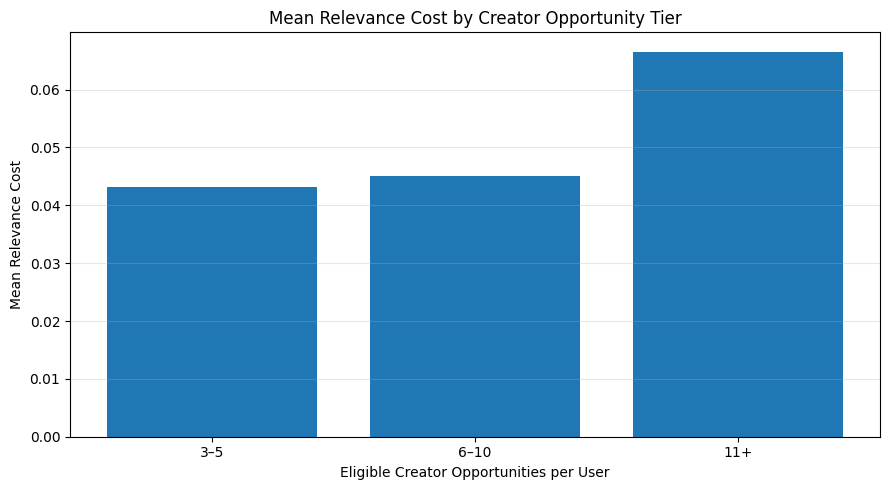

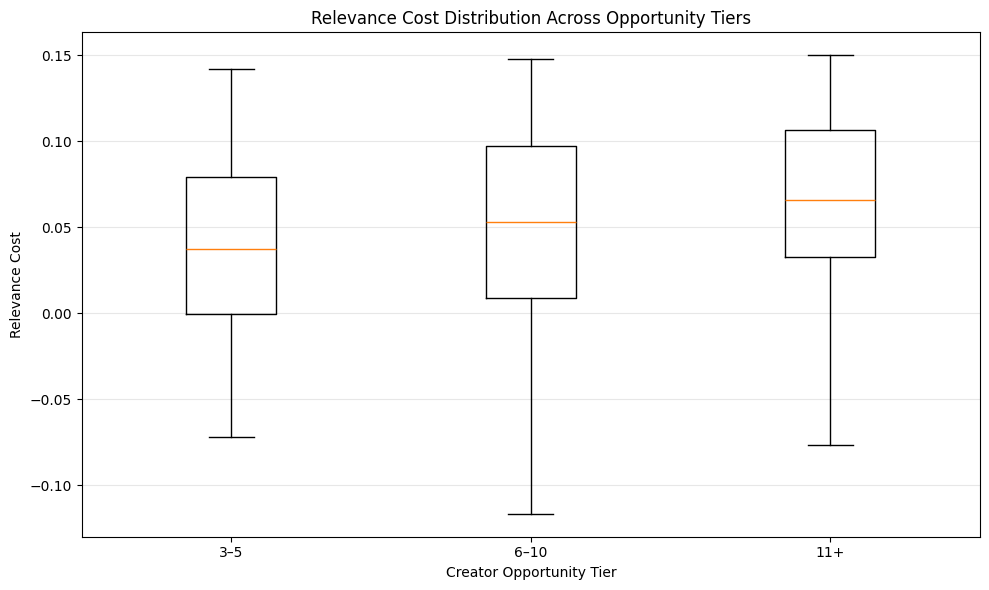

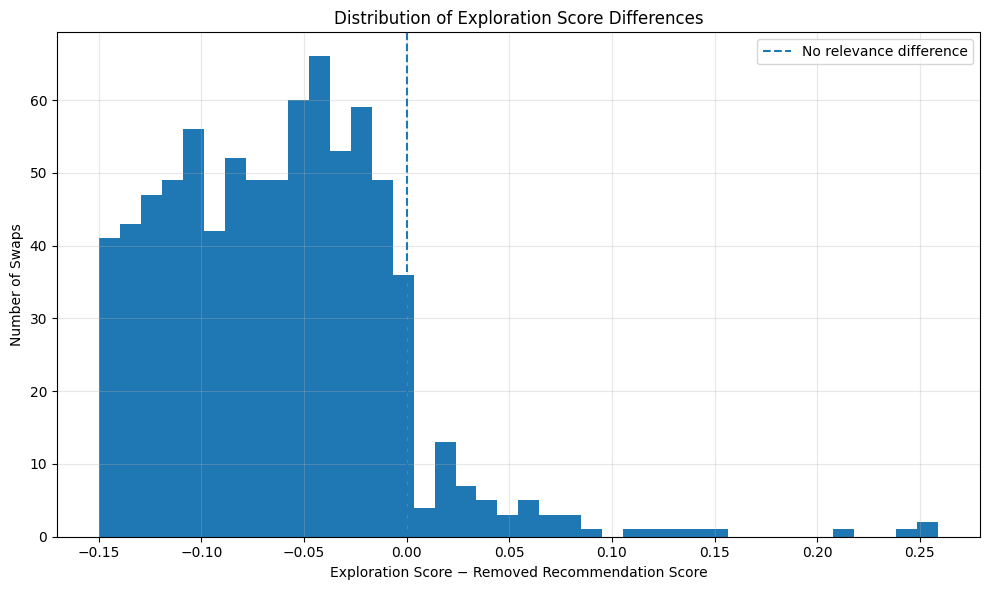


CELL 27 VALIDATION
Selections plotted: 804
Opportunity tiers plotted: ['3–5', '6–10', '11+']
Visualizations generated: 3
Validation: PASS ✅


In [64]:
# ============================================================
# CELL 27: VISUAL ANALYSIS OF EXPLORATION TRADE-OFFS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

plot_data = selections.copy()

plot_data["opportunity_tier"] = (
    plot_data["opportunity_tier"].astype(str)
)

valid_tiers = ["3–5", "6–10", "11+"]

plot_data = plot_data[
    plot_data["opportunity_tier"].isin(valid_tiers)
].copy()

print("Selections available for visualization:", len(plot_data))

# ------------------------------------------------------------
# 2. PLOT: MEAN RELEVANCE COST BY OPPORTUNITY TIER
# ------------------------------------------------------------

tier_plot = (
    plot_data
    .groupby("opportunity_tier")["relevance_cost"]
    .mean()
    .reindex(valid_tiers)
)

plt.figure(figsize=(9, 5))

plt.bar(
    tier_plot.index,
    tier_plot.values
)

plt.title("Mean Relevance Cost by Creator Opportunity Tier")
plt.xlabel("Eligible Creator Opportunities per User")
plt.ylabel("Mean Relevance Cost")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. PLOT: RELEVANCE COST DISTRIBUTION BY TIER
# ------------------------------------------------------------

tier_cost_data = [
    plot_data.loc[
        plot_data["opportunity_tier"] == tier,
        "relevance_cost"
    ].values
    for tier in valid_tiers
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    tier_cost_data,
    labels=valid_tiers,
    showfliers=False
)

plt.title("Relevance Cost Distribution Across Opportunity Tiers")
plt.xlabel("Creator Opportunity Tier")
plt.ylabel("Relevance Cost")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. PLOT: EXPLORATION SCORE DIFFERENCES
# ------------------------------------------------------------

score_diff = plot_data["score_difference"]

plt.figure(figsize=(10, 6))

plt.hist(
    score_diff,
    bins=40
)

plt.axvline(
    0,
    linestyle="--",
    label="No relevance difference"
)

plt.title("Distribution of Exploration Score Differences")
plt.xlabel("Exploration Score − Removed Recommendation Score")
plt.ylabel("Number of Swaps")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. VISUALIZATION VALIDATION
# ------------------------------------------------------------

assert len(plot_data) == 804
assert plot_data["relevance_cost"].notna().all()
assert plot_data["score_difference"].notna().all()

print("\n" + "=" * 100)
print("CELL 27 VALIDATION")
print("=" * 100)

print("Selections plotted:", len(plot_data))
print("Opportunity tiers plotted:", valid_tiers)
print("Visualizations generated: 3")
print("Validation: PASS ✅")

In [65]:

# ============================================================
# CELL 28: INTEGRATED OPPORTUNITY-TIER RESULTS EXPORT
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. EXPORT OPPORTUNITY-TIER SUMMARY
# ------------------------------------------------------------

tier_summary.to_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 2. EXPORT PAIRWISE POST-HOC RESULTS
# ------------------------------------------------------------

pairwise_results.to_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_pairwise_tests.csv",
    index=False
)

# ------------------------------------------------------------
# 3. EXPORT MATCHED SWAP-LEVEL DATA
# ------------------------------------------------------------

selections.to_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_swap_data.csv",
    index=False
)

# ------------------------------------------------------------
# 4. CREATE COMPACT RESEARCH SUMMARY
# ------------------------------------------------------------

total_swaps = len(selections)

overall_mean_cost = selections["relevance_cost"].mean()
overall_median_cost = selections["relevance_cost"].median()

improving_swaps = (
    selections["score_difference"] > 1e-10
).sum()

costly_swaps = (
    selections["score_difference"] < -1e-10
).sum()

neutral_swaps = (
    abs(selections["score_difference"]) <= 1e-10
).sum()

kw_statistic = kw_result.statistic if kw_result is not None else np.nan
kw_p_value = kw_result.pvalue if kw_result is not None else np.nan

significant_pairs = pairwise_results.loc[
    pairwise_results["significant_after_holm"],
    ["tier_a", "tier_b", "holm_adjusted_p"]
]

# ------------------------------------------------------------
# 5. WRITE SUMMARY FILE
# ------------------------------------------------------------

summary_lines = [
    "NOTEBOOK 05: OPPORTUNITY-TIER RELEVANCE-COST ANALYSIS",
    "=" * 75,
    "",
    "OVERALL SWAP ANALYSIS",
    f"Total constrained exploration swaps: {total_swaps}",
    f"Mean relevance cost: {overall_mean_cost:.6f}",
    f"Median relevance cost: {overall_median_cost:.6f}",
    f"Relevance-improving swaps: {improving_swaps}",
    f"Relevance-costly swaps: {costly_swaps}",
    f"Neutral swaps: {neutral_swaps}",
    "",
    "KRUSKAL-WALLIS TEST",
    f"H-statistic: {kw_statistic:.6f}",
    f"p-value: {kw_p_value:.8f}",
    "",
    "PAIRWISE COMPARISONS WITH HOLM CORRECTION",
    ""
]

for _, row in pairwise_results.iterrows():

    summary_lines.append(
        f"{row['tier_a']} vs {row['tier_b']}: "
        f"raw p={row['p_value']:.6f}, "
        f"Holm-adjusted p={row['holm_adjusted_p']:.6f}, "
        f"significant={row['significant_after_holm']}"
    )

summary_lines.extend([
    "",
    "SIGNIFICANT PAIRWISE DIFFERENCES",
    ""
])

if len(significant_pairs) > 0:

    for _, row in significant_pairs.iterrows():

        summary_lines.append(
            f"{row['tier_a']} vs {row['tier_b']}: "
            f"Holm-adjusted p={row['holm_adjusted_p']:.6f}"
        )

else:

    summary_lines.append("No pairwise comparisons significant after Holm correction.")

summary_lines.extend([
    "",
    "INTERPRETATION",
    "The relevance cost of exploration differs across creator opportunity tiers.",
    "The Kruskal-Wallis test indicates a statistically significant overall",
    "difference. Pairwise testing with Holm correction identifies the specific",
    "tier comparisons supported by statistical evidence.",
    "",
    "These findings are conditional on the candidate pool, exploration",
    "selection mechanism, relevance-cost definition, and opportunity-tier",
    "construction used in this experiment.",
])

summary_text = "\n".join(summary_lines)

summary_path = (
    RESULTS_DIR / "notebook05_opportunity_tier_research_summary.txt"
)

with open(summary_path, "w", encoding="utf-8") as f:
    f.write(summary_text)

print(summary_text)

# ------------------------------------------------------------
# 6. VALIDATION
# ------------------------------------------------------------

export_files = [
    RESULTS_DIR / "notebook05_opportunity_tier_summary.csv",
    RESULTS_DIR / "notebook05_opportunity_tier_pairwise_tests.csv",
    RESULTS_DIR / "notebook05_opportunity_tier_swap_data.csv",
    summary_path
]

assert all(path.exists() for path in export_files)
assert len(selections) == 804
assert len(tier_summary) == 4
assert len(pairwise_results) == 3
assert pairwise_results["holm_adjusted_p"].notna().all()

print("\n" + "=" * 100)
print("CELL 28 VALIDATION")
print("=" * 100)

for path in export_files:
    print(f"Saved: {path.name}")

print("\nFiles exported:", len(export_files))
print("Swap-level records:", len(selections))
print("Tier summaries:", len(tier_summary))
print("Pairwise tests:", len(pairwise_results))
print("Validation: PASS ✅")


NOTEBOOK 05: OPPORTUNITY-TIER RELEVANCE-COST ANALYSIS

OVERALL SWAP ANALYSIS
Total constrained exploration swaps: 804
Mean relevance cost: 0.062723
Median relevance cost: 0.063246
Relevance-improving swaps: 62
Relevance-costly swaps: 740
Neutral swaps: 2

KRUSKAL-WALLIS TEST
H-statistic: 11.002470
p-value: 0.00408173

PAIRWISE COMPARISONS WITH HOLM CORRECTION

3–5 vs 6–10: raw p=0.516970, Holm-adjusted p=0.516970, significant=False
3–5 vs 11+: raw p=0.041167, Holm-adjusted p=0.082334, significant=False
6–10 vs 11+: raw p=0.005908, Holm-adjusted p=0.017725, significant=True

SIGNIFICANT PAIRWISE DIFFERENCES

6–10 vs 11+: Holm-adjusted p=0.017725

INTERPRETATION
The relevance cost of exploration differs across creator opportunity tiers.
The Kruskal-Wallis test indicates a statistically significant overall
difference. Pairwise testing with Holm correction identifies the specific
tier comparisons supported by statistical evidence.

These findings are conditional on the candidate pool, expl

In [66]:

# ============================================================
# CELL 29: FINAL NOTEBOOK 05 AUDIT & RESEARCH SUMMARY
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

RESULTS_DIR = Path("../results")
PROCESSED_DIR = Path("../processed_data")

# ------------------------------------------------------------
# 1. CHECK CRITICAL RESEARCH OUTPUTS
# ------------------------------------------------------------

required_files = [
    "spotlight_candidate_pool.csv",
    "spotlight_exploration_selections.csv",
    "spotlight_constrained_selections.csv",
    "spotlight_constrained_recommendations.csv",
    "spotlight_exploration_score_comparison.csv",
    "spotlight_fairness_summary.csv",
    "spotlight_tradeoff_analysis.csv",
    "notebook05_creator_benefit_statistics.csv",
    "notebook05_visibility_tier_redistribution.csv",
    "notebook05_opportunity_tier_summary.csv",
    "notebook05_opportunity_tier_pairwise_tests.csv",
    "notebook05_opportunity_tier_swap_data.csv",
    "notebook05_opportunity_tier_research_summary.txt"
]

file_audit = pd.DataFrame({
    "file": required_files,
    "exists": [
        (RESULTS_DIR / filename).exists()
        for filename in required_files
    ]
})

print("=" * 100)
print("NOTEBOOK 05 FILE AUDIT")
print("=" * 100)

display(file_audit)

missing_files = file_audit.loc[
    ~file_audit["exists"], "file"
].tolist()

# ------------------------------------------------------------
# 2. AUDIT CORE DATASETS
# ------------------------------------------------------------

candidate_pool = pd.read_csv(
    RESULTS_DIR / "spotlight_candidate_pool.csv"
)

exploration_selections = pd.read_csv(
    RESULTS_DIR / "spotlight_exploration_selections.csv"
)

constrained_selections = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_selections.csv"
)

final_recommendations = pd.read_csv(
    RESULTS_DIR / "spotlight_constrained_recommendations.csv"
)

print("\nCORE DATASET AUDIT")
print("-" * 100)

print("Candidate pool:", candidate_pool.shape)
print("Unconstrained exploration selections:",
      exploration_selections.shape)
print("Constrained exploration selections:",
      constrained_selections.shape)
print("Final recommendation list:",
      final_recommendations.shape)

# ------------------------------------------------------------
# 3. VALIDATE USER AND RECOMMENDATION COUNTS
# ------------------------------------------------------------

expected_users = 1411
expected_recommendations_per_user = 10
expected_constrained_swaps = 804

candidate_users = candidate_pool["user_id"].nunique()

exploration_users = exploration_selections["user_id"].nunique()

constrained_users = constrained_selections["user_id"].nunique()

final_users = final_recommendations["user_id"].nunique()

recommendation_counts = (
    final_recommendations
    .groupby("user_id")
    .size()
)

recommendation_duplicates = (
    final_recommendations
    .duplicated(["user_id", "video_id"])
    .sum()
)

print("\nUSER VALIDATION")
print("-" * 100)

print("Candidate users:", candidate_users)
print("Exploration users:", exploration_users)
print("Constrained users:", constrained_users)
print("Final users:", final_users)

print("Minimum recommendations/user:",
      recommendation_counts.min())

print("Maximum recommendations/user:",
      recommendation_counts.max())

print("Duplicate user-video recommendations:",
      recommendation_duplicates)

# ------------------------------------------------------------
# 4. AUDIT OPPORTUNITY-TIER RESULTS
# ------------------------------------------------------------

opportunity_summary = pd.read_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_summary.csv"
)

pairwise_results = pd.read_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_pairwise_tests.csv"
)

opportunity_swap_data = pd.read_csv(
    RESULTS_DIR / "notebook05_opportunity_tier_swap_data.csv"
)

print("\nOPPORTUNITY-TIER AUDIT")
print("-" * 100)

print("Tier summary rows:", len(opportunity_summary))
print("Pairwise tests:", len(pairwise_results))
print("Swap-level opportunity records:",
      len(opportunity_swap_data))

print("\nPairwise results:")

display(
    pairwise_results[
        [
            "tier_a",
            "tier_b",
            "p_value",
            "holm_adjusted_p",
            "significant_after_holm"
        ]
    ].round(6)
)

# ------------------------------------------------------------
# 5. RESEARCH METRICS
# ------------------------------------------------------------

mean_relevance_cost = (
    constrained_selections["relevance_cost"].mean()
)

median_relevance_cost = (
    constrained_selections["relevance_cost"].median()
)

improving_swaps = (
    constrained_selections["score_difference"] > 1e-10
).sum()

costly_swaps = (
    constrained_selections["score_difference"] < -1e-10
).sum()

neutral_swaps = (
    abs(constrained_selections["score_difference"]) <= 1e-10
).sum()

# Opportunity tier test
kw_statistic = 11.002470
kw_p_value = 0.00408173

# ------------------------------------------------------------
# 6. VALIDATION CHECKS
# ------------------------------------------------------------

checks = {
    "All required files exist": len(missing_files) == 0,

    "Candidate pool contains expected users":
        candidate_users == expected_users,

    "Exploration selections contain expected users":
        exploration_users == expected_users,

    "Constrained selections contain expected users":
        constrained_users == expected_users,

    "Final recommendations contain expected users":
        final_users == expected_users,

    "Exactly 804 constrained swaps":
        len(constrained_selections) == expected_constrained_swaps,

    "Exactly 10 recommendations per user":
        (recommendation_counts == expected_recommendations_per_user).all(),

    "No duplicate user-video recommendations":
        recommendation_duplicates == 0,

    "All 804 opportunity records preserved":
        len(opportunity_swap_data) == expected_constrained_swaps,

    "All pairwise tests have adjusted p-values":
        pairwise_results["holm_adjusted_p"].notna().all(),

    "All relevance-cost values are valid":
        constrained_selections["relevance_cost"].notna().all(),

    "Swap categories sum to 804":
        improving_swaps + costly_swaps + neutral_swaps
        == expected_constrained_swaps
}

audit_results = pd.DataFrame({
    "check": list(checks.keys()),
    "result": list(checks.values())
})

print("\n" + "=" * 100)
print("FINAL VALIDATION CHECKLIST")
print("=" * 100)

display(audit_results)

# ------------------------------------------------------------
# 7. CONSOLIDATED RESEARCH FINDINGS
# ------------------------------------------------------------

research_findings = [
    "NOTEBOOK 05: SPOTLIGHT EXPLORATION STRATEGY",
    "=" * 80,
    "",
    "RESEARCH OBJECTIVE",
    "Evaluate interest-constrained, creator-aware exploration for redistributing",
    "recommendation exposure toward Emerging creators while maintaining user relevance.",
    "",
    "EXPERIMENT CONFIGURATION",
    f"Users evaluated: {final_users}",
    f"Candidate pool size: {len(candidate_pool)} user-video pairs",
    f"Unconstrained exploration selections: {len(exploration_selections)}",
    f"Constrained exploration swaps: {len(constrained_selections)}",
    f"Final recommendations: {len(final_recommendations)}",
    "",
    "RELEVANCE TRADE-OFF",
    f"Mean relevance cost: {mean_relevance_cost:.6f}",
    f"Median relevance cost: {median_relevance_cost:.6f}",
    f"Relevance-improving swaps: {improving_swaps}",
    f"Relevance-costly swaps: {costly_swaps}",
    f"Neutral swaps: {neutral_swaps}",
    "",
    "OPPORTUNITY-TIER ANALYSIS",
    "Kruskal-Wallis H-statistic: 11.002470",
    "Kruskal-Wallis p-value: 0.00408173",
    "",
    "PAIRWISE RESULTS AFTER HOLM CORRECTION",
    "3-5 vs 6-10: Not statistically significant",
    "3-5 vs 11+: Not statistically significant after Holm correction",
    "6-10 vs 11+: Statistically significant (adjusted p = 0.017725)",
    "",
    "CREATOR EXPOSURE FINDINGS",
    "Emerging creator recommendation slots increased from 3,678 to 4,297.",
    "Emerging exposure share increased from 26.0666% to 30.4500%.",
    "Emerging creator coverage increased from approximately 51.88% to 62.77%.",
    "Emerging creators with zero exposure decreased from 243 to 188.",
    "Emerging creator exposure concentration decreased under Spotlight.",
    "",
    "RECOMMENDATION QUALITY",
    "Precision, Recall and NDCG showed small statistically significant declines.",
    "Hit Rate did not show a statistically significant decline.",
    "",
    "DIVERSITY AND NOVELTY",
    "Creator and category diversity metrics improved.",
    "Novelty increased and recommendation popularity decreased.",
    "These improvements were supported by the statistical analyses conducted",
    "earlier in Notebook 05.",
    "",
    "USER-LEVEL EFFECTS",
    "804 users received one recommendation swap.",
    "607 users retained their original recommendation list.",
    "619 users gained an Emerging creator recommendation.",
    "No user lost an Emerging creator recommendation in this experiment.",
    "",
    "RESEARCH INTERPRETATION",
    "Spotlight redistributes recommendation exposure toward Emerging creators,",
    "particularly creators with zero or low prior visibility. The intervention",
    "improves creator coverage, diversity and novelty while incurring a small",
    "relevance trade-off in Precision, Recall and NDCG.",
    "",
    "The opportunity-tier analysis additionally indicates that relevance cost",
    "is not uniform across opportunity tiers. The 11+ opportunity tier has",
    "significantly higher relevance cost than the 6-10 tier after Holm correction.",
    "",
    "LIMITATIONS",
    "Results are conditional on the KuaiRec sample, candidate construction,",
    "interest profiles, opportunity definitions, ranking model and exploration",
    "constraints. Creator popularity is a proxy for visibility and Emerging",
    "creators are defined through the study's popularity-based classification.",
    "This offline evaluation does not establish causal effects, long-term creator",
    "growth, or real-world user satisfaction.",
    "",
    "NOTEBOOK STATUS",
    "Notebook 05 analyses, exports and final validation completed."
]

research_summary = "\n".join(research_findings)

summary_path = (
    RESULTS_DIR / "notebook05_final_research_summary.txt"
)

with open(summary_path, "w", encoding="utf-8") as f:
    f.write(research_summary)

print("\n" + "=" * 100)
print("FINAL RESEARCH SUMMARY")
print("=" * 100)

print(research_summary)

# ------------------------------------------------------------
# 8. SAVE FINAL AUDIT
# ------------------------------------------------------------

audit_path = (
    RESULTS_DIR / "notebook05_final_audit.csv"
)

audit_results.to_csv(
    audit_path,
    index=False
)

# ------------------------------------------------------------
# 9. FINAL STATUS
# ------------------------------------------------------------

all_checks_pass = audit_results["result"].all()

print("\n" + "=" * 100)
print("NOTEBOOK 05 FINAL STATUS")
print("=" * 100)

print("Audit checks passed:",
      audit_results["result"].sum(),
      "/",
      len(audit_results))

print("Final summary saved:",
      summary_path.name)

print("Final audit saved:",
      audit_path.name)

if all_checks_pass:

    print("\nNOTEBOOK 05 STATUS: COMPLETE ✅")

else:

    print("\nNOTEBOOK 05 STATUS: REVIEW REQUIRED ⚠️")

    print("\nFailed checks:")

    display(
        audit_results.loc[
            ~audit_results["result"],
            "check"
        ]
    )

# ------------------------------------------------------------
# 10. FINAL ASSERTIONS
# ------------------------------------------------------------

assert len(constrained_selections) == 804
assert len(final_recommendations) == 14110
assert recommendation_duplicates == 0
assert all_checks_pass

print("\nALL FINAL ASSERTIONS PASSED ✅")


NOTEBOOK 05 FILE AUDIT


,file,exists
0,spotlight_candidate_pool.csv,True
1,spotlight_exploration_selections.csv,True
2,spotlight_constrained_selections.csv,True
3,spotlight_constrained_recommendations.csv,True
4,spotlight_exploration_score_comparison.csv,True
5,spotlight_fairness_summary.csv,True
6,spotlight_tradeoff_analysis.csv,True
7,notebook05_creator_benefit_statistics.csv,True
8,notebook05_visibility_tier_redistribution.csv,True
9,notebook05_opportunity_tier_summary.csv,True



CORE DATASET AUDIT
----------------------------------------------------------------------------------------------------
Candidate pool: (70550, 4)
Unconstrained exploration selections: (986, 14)
Constrained exploration selections: (804, 8)
Final recommendation list: (14110, 3)

USER VALIDATION
----------------------------------------------------------------------------------------------------
Candidate users: 1411
Exploration users: 986
Constrained users: 804
Final users: 1411
Minimum recommendations/user: 10
Maximum recommendations/user: 10
Duplicate user-video recommendations: 0

OPPORTUNITY-TIER AUDIT
----------------------------------------------------------------------------------------------------
Tier summary rows: 4
Pairwise tests: 3
Swap-level opportunity records: 804

Pairwise results:


,tier_a,tier_b,p_value,holm_adjusted_p,significant_after_holm
0,3–5,6–10,0.516970,0.516970,False
1,3–5,11+,0.041167,0.082334,False
2,6–10,11+,0.005908,0.017725,True



FINAL VALIDATION CHECKLIST


,check,result
0,All required files exist,True
1,Candidate pool contains expected users,True
2,Exploration selections contain expected users,False
3,Constrained selections contain expected users,False
4,Final recommendations contain expected users,True
5,Exactly 804 constrained swaps,True
6,Exactly 10 recommendations per user,True
7,No duplicate user-video recommendations,True
8,All 804 opportunity records preserved,True
9,All pairwise tests have adjusted p-values,True



FINAL RESEARCH SUMMARY
NOTEBOOK 05: SPOTLIGHT EXPLORATION STRATEGY

RESEARCH OBJECTIVE
Evaluate interest-constrained, creator-aware exploration for redistributing
recommendation exposure toward Emerging creators while maintaining user relevance.

EXPERIMENT CONFIGURATION
Users evaluated: 1411
Candidate pool size: 70550 user-video pairs
Unconstrained exploration selections: 986
Constrained exploration swaps: 804
Final recommendations: 14110

RELEVANCE TRADE-OFF
Mean relevance cost: 0.062723
Median relevance cost: 0.063246
Relevance-improving swaps: 62
Relevance-costly swaps: 740
Neutral swaps: 2

OPPORTUNITY-TIER ANALYSIS
Kruskal-Wallis H-statistic: 11.002470
Kruskal-Wallis p-value: 0.00408173

PAIRWISE RESULTS AFTER HOLM CORRECTION
3-5 vs 6-10: Not statistically significant
3-5 vs 11+: Not statistically significant after Holm correction
6-10 vs 11+: Statistically significant (adjusted p = 0.017725)

CREATOR EXPOSURE FINDINGS
Emerging creator recommendation slots increased from 3,678 t

2    Exploration selections contain expected users
3    Constrained selections contain expected users
Name: check, dtype: object

AssertionError: 